# Where Llama goes when an algorithm is banned: `method.py` demo

**Artifact:** experiment 15 · **Model:** Llama-3.1-8B-Instruct (bf16, revision `0e9e39f`) · **Bench:** the frozen 12-task coding bench (exp11)

Tell an LLM *"Do not use X for this task"*, where X is the algorithm it writes by default. What does it write instead? **Claim 1** says the ban removes the default and the model falls to a *predictable next rung*. This artifact tests that claim on Llama-3.1-8B-Instruct. Before a single ban prompt is rendered, it commits four **ban-free forecast families** for where the model will land:

| family | ban-free source of the forecast |
|---|---|
| **SUBTRACT** | where the model lands when X's signature token n-grams are vetoed during decoding (truncate-and-redraw in vLLM) |
| **LADDER** | where it lands under generic pushes: a nonce ban ("the Zorblax method"), a novelty instruction, and 3 matched-norm random directions added to the task-spec positions of layers 11–21 |
| **ASSOCIATE** | Llama's own answer to "what is the standard alternative to X for this task?" |
| **PROXIMITY** | the surviving algorithm whose programs are closest to X's programs (Zhang-Shasha tree-edit distance on identifier-normalised ASTs) |

The forecasts are sha256 hash-chained in `commitments.log`. Only then are 1,800 bans sampled: 18 events (12 modal defaults and 6 present-minor algorithms) × 5 ban templates × 20 samples. They are scored with the frozen **C1 rule**: a smoothed log score, an avoidance gate, a ≥ 0.10-nat margin for a win and ≥ 3 wins to advance, plus Wilcoxon + Holm and top-1 binomial tests.

**Recorded result.** 13 events pass the gate and 11 of them have families that disagree. Only 2 have a winner, so the branch is **"NO FAMILY ADVANCES (aimed, unresolved)"**. SUBTRACT and LADDER beat PROXIMITY (Wilcoxon p = 0.0029 / 0.0020, Holm-rejected). LADDER and ASSOCIATE each name the realised landing on 7 of 13 gated events (binomial p = 0.033 against chance).

### What runs in this notebook

`method.py` is a CLI with one sub-command per stage. Some stages need an L4 GPU running vLLM with `Llama-3.1-8B-Instruct`, Hugging Face hidden-state passes or steering hooks, or the OpenRouter judge; none of these fits a 10-minute CPU notebook. Those stages are shown as **reference code** in markdown, and their **recorded outputs** come from `mini_demo_data.json`: the final combined label of every generation. Every CPU stage **runs for real** on those labels with the original code:

| stage (`method.py <cmd>`) | needs | in this notebook |
|---|---|---|
| `setup`, `gen1`, `hf`, `push`, `veto`, `ban`, `screen` | L4 GPU, vLLM 0.11, Llama weights | reference code + recorded outputs |
| `label` | bench test harness + OpenRouter judge | recorded combined labels |
| `freeze` (C4/C5) | CPU | ✅ FFH homogeneity test, frozen default D, present-minor events |
| `assoc` (C6) | CPU | ✅ ASSOCIATE targets from Llama's association answers |
| `proximity` | CPU (~0.3–1.6 s per AST pair) | ✅ Zhang-Shasha nominations on 1–3 events (config) |
| `commit` (F) | CPU | ✅ forecasts rebuilt, sha256 hash chain verified |
| `analyse` (H) | CPU | ✅ frozen C1 scoring, Wilcoxon/Holm, binomial, sensitivities |
| `audit/rederive_tests.py` | CPU | ✅ independent re-derivation with placebos |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (method.py logging), zss (Zhang-Shasha tree edit distance), rapidfuzz (bench canonical-token Levenshtein)
# — NOT on Colab, always install (versions pinned as in the artifact's pyproject.toml)
_pip('loguru==0.7.3', 'zss==1.2.0', 'rapidfuzz==3.14.1')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py imports (original)
import argparse
import sys
import time
from pathlib import Path

from loguru import logger

# ---- imports of the src/ modules whose CPU code is inlined below (ws, stats_util, scoring, commit, freeze,
#      forecasts, proximity + the bench's canon.py, analysis, figures) and of audit/rederive_tests.py
import ast
import builtins
import collections
import datetime as dt
import hashlib
import io
import itertools
import json
import keyword
import math
import os
import random
import statistics
import tokenize
import types
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from typing import Any, Iterable

import numpy as np
from rapidfuzz.distance import Levenshtein

# ---- notebook additions: tables and figures
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-15/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

EVENTS_DATA = data["datasets"][0]["examples"]   # the one dataset: llama_bench_events (all 18 frozen ban events)
CTX = data["context"]                          # task-level rows: decision sets, pushes, association answers, ...
print(data["metadata"]["title"])
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EVENTS_DATA)} events")
for e in EVENTS_DATA:
    print(f"  {e['event_id']:<34} ban rows={len(e['ban_rows']):>3}  veto rows={len(e['veto_rows']):>3}")
print({k: len(v) for k, v in CTX.items()})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where Llama goes when an algorithm is banned (experiment 15) - demo subset
dataset 'llama_bench_events': 18 events
  T03|modal|full_sort                ban rows=100  veto rows=100
  T04|modal|naive                    ban rows=100  veto rows=200
  T06|modal|hash_set                 ban rows=100  veto rows=200
  T05|modal|hash_map                 ban rows=100  veto rows=200
  T10|modal|union_find               ban rows=100  veto rows=200
  R1|modal|greedy_end                ban rows=100  veto rows=200
  T08|modal|matrix_power             ban rows=100  veto rows=200
  R3|modal|kahn                      ban rows=100  veto rows=200
  T13|modal|sort_sweep               ban rows=100  veto rows=200
  R6|modal|binary_search             ban rows=100  veto rows=200
  T14|modal|heap                     ban rows=100  veto rows=150
  T11|modal|quadratic_dp             ban rows=100  veto rows=200
  T14|present_minor|s

## Configuration

All tunable parameters live here. The comments give the values the artifact used. Everything except PROXIMITY runs at the original values within the time budget. The Zhang-Shasha tree-edit distance is pure Python and costs about 0.3–1.6 s per program pair, and the original run needed 829 s on 4 processes for all 18 events. The demo therefore recomputes the PROXIMITY nomination for 2 of the 3 shipped events (T05 and R6) at the original `k_used = 6`; set `PROX_N_EVENTS = 3` to add T13, which costs another 2–5 minutes. Every forecast uses the **committed** nominations, exactly as in the original pipeline.

In [5]:
# ---- tunable parameters (original values in the comments)
FFH_DRAWS = 100_000      # Fisher-Freeman-Halton Monte Carlo draws per task (freeze: decision-set homogeneity); original 100_000
N_BOOT = 2000            # task-cluster bootstrap resamples (aggregate CIs, forest figure); original 2000
C2B_NULL_DRAWS = 1000    # template-bootstrap null draws of the C2b JSD comparison (H4); original 1000
RAREFY_REPS = 2000       # rarefied Hill-1 replicates (diversity of correct landings); original 2000
N_PLACEBO = 1000         # placebo permutations / draws in the independent re-derivation; original 1000
PROX_N_EVENTS = 2        # PROXIMITY events recomputed here, in order T05, R6, T13 (3 shipped; T13 adds 2-5 min); original: all 18
PROX_K = 6               # programs sampled per side for Zhang-Shasha pairs; original k=10, cut to k_used=6 by the 2,400 s budget
PROX_K_TOK = 30          # programs per side for the canonical-token Levenshtein sensitivity; original 30
PROX_WORKERS = 1         # worker threads; pure-Python Zhang-Shasha holds the GIL, so 1 is fastest (original: 4 spawn processes)

# method.py's CLI arguments (argparse) for the sub-commands called below
args = argparse.Namespace(phases="", workers=PROX_WORKERS, limit=0, no_judge=True)

## 1 · Workspace bridge (`src/ws.py`) and the demo data on disk

`method.py` takes its paths, frozen constants and JSON helpers from `src/ws.py`; the cell below is that code. The only change is the workspace root: a local folder `llama_ban_demo/` instead of the artifact directory. The helper that downloads the model is omitted. The frozen protocol is visible in the constants: 12 tasks, the five ban templates W1–W5, the nonce and novelty pushes, steering at layers 11–21, and the smoothing 0.93 / 0.05 / 0.02.

In [6]:
# ---- src/ws.py (workspace root = a local folder instead of the artifact directory)
WS = Path("llama_ban_demo")
INPUTS = WS / "inputs"
DATA = WS / "data"
RESULTS = WS / "results"
PRED = WS / "predictions"
LOGS = WS / "logs"
FIGS = WS / "figures"
for _d in (DATA, RESULTS, PRED, LOGS, FIGS):
    _d.mkdir(parents=True, exist_ok=True)
DATA_DIR = DATA  # method.py: from src.ws import DATA as DATA_DIR

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
MODEL_REV = "0e9e39f249a16976918f6564b8830bc894c89659"
MODEL_TAG = "meta-llama/Llama-3.1-8B-Instruct@0e9e39f(bf16)"
DATE_STRING = "26 Jul 2024"
EOS_IDS = [128001, 128008, 128009]
MAX_TOKENS = 1024
ASSOC_MAX_TOKENS = 96
FROZEN_TASKS = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
PUSH_LAYERS = list(range(11, 22))       # decoder layers 11..21 (hidden_states[l+1] in HF)
RANDDIR_SEEDS = [20261020, 20261021, 20261022]
TEMPLATES = {
    1: "Do not use {X} for this task.",
    2: "Your solution must not rely on {X}.",
    3: "Avoid {X} entirely.",
    4: "{X} is not allowed here.",
    5: "Write a correct solution that does not use {X}.",
}
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}


def request_seed(task: str, cond: str, tpl: Any, sample_id: Any) -> int:
    """exp10 rule: int(sha256('task|cond|tpl|sample_id')[:8], 16)."""
    return int(hashlib.sha256(f"{task}|{cond}|{tpl}|{sample_id}".encode()).hexdigest()[:8], 16)


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _default(o: Any) -> Any:
    try:
        import numpy as np

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def clean_nan(o: Any) -> Any:
    if isinstance(o, float) and not math.isfinite(o):
        return None
    if isinstance(o, dict):
        return {str(k): clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    lines = p.read_text().splitlines()
    for i, line in enumerate(lines):
        line = line.strip()
        if not line:
            continue
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1:  # a concurrently appended, not yet complete last line
                continue
            raise
    return out


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> int:
    n = 0
    with Path(p).open("w") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), ensure_ascii=False, default=_default) + "\n")
            n += 1
    return n


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    Path(p).write_text(json.dumps(clean_nan(obj), indent=indent, ensure_ascii=False, default=_default))


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def setup_logging(name: str) -> None:
    from loguru import logger

    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


setup_logging("method_demo")
assert FROZEN_TASKS == data["metadata"]["frozen_tasks"]

### Demo data → the artifact's file layout

The CPU stages read files written by the GPU stages and by the labeller:

- `data/labels.jsonl`: the final combined label of every program. It comes from the bench's runtime tracer and AST rules, with a blind LLM judge on disagreements.
- `data/raw_gen.jsonl`: one raw record per generation.
- `data/association.jsonl`: the mapped association answers.
- `predictions/x0.json` and `results/*audit*.json`.

The cell below writes demo-data versions of these files into the local workspace, so the original `read_json` / `read_jsonl` calls run unchanged. The raw records keep only the fields the CPU code reads, without the generated text. For each ban sample, `mentions` holds the bench lexicon's `mentions(task, text)` result, precomputed from that sample's response. It is used for the disguise rate: a banned algorithm written without being named.

It also defines thin stand-ins for the three `src` modules whose other functions need the model, the tokenizer or the judge. From `jobs.py` and `label.py` the stand-ins keep `raw_rows`, `pilot_rows` and the label file paths; from `prompts_llama.py` they keep the catalogue lookups `modes` and `display`.

In [7]:
# ---- the input files of the CPU stages, written from the demo data
labels_rows = list(CTX["labels_pilot_B1_B4"]) + list(CTX["labels_push_B5_E3"])
raw_rows_all = list(CTX["raw_B1_B4"])
for ex in EVENTS_DATA:
    for r in ex["ban_rows"]:     # G1/G2: the 100 ban samples of the event (5 templates x 20)
        labels_rows.append({k: r[k] for k in ("row_id", "task", "phase", "label", "passed")})
        raw_rows_all.append({"row_id": r["row_id"], "phase": r["phase"], "task": r["task"], "event_id": ex["event_id"],
                             "template": r["template"], "mode": ex["banned"], "mentions": r["mentions"]})
    for r in ex["veto_rows"]:    # D2/D3: one-shot and persistent/iterated veto rounds behind SUBTRACT
        labels_rows.append({"row_id": r["row_id"], "task": r["task"], "phase": r["phase"], "label": r["label"]})
        raw_rows_all.append({k: v for k, v in r.items() if k != "label"})
write_jsonl(DATA / "labels.jsonl", labels_rows)
write_jsonl(DATA / "raw_gen.jsonl", raw_rows_all)
write_jsonl(DATA / "association.jsonl", CTX["association_B2"])
write_json(PRED / "x0.json", data["metadata"]["x0_json"])
write_json(RESULTS / "llama_label_audit.json", data["metadata"]["label_audit"])
write_json(RESULTS / "other_reaudit.json", data["metadata"]["other_reaudit"])


# ---- src/jobs.py: raw generation records
RAW = DATA / "raw_gen.jsonl"


def raw_rows(phases: set[str] | None = None) -> list[dict[str, Any]]:
    rows = read_jsonl(RAW)
    return [r for r in rows if phases is None or r["phase"] in phases]


# ---- src/label.py: label files; the exp11 FP8 pilot rows (their texts are not shipped: id, phase and task only)
def pilot_rows() -> list[dict[str, Any]]:
    return [{"row_id": r["row_id"], "phase": "pilot", "task": r["task"], "condition": "pilot_fp8"}
            for r in read_jsonl(DATA / "labels.jsonl") if r.get("phase") == "pilot"]


L = types.SimpleNamespace(LABELS=DATA / "labels.jsonl", ASSOC=DATA / "association.jsonl", pilot_rows=pilot_rows)

# ---- src/prompts_llama.py: catalogue lookups (bench spec.json catalogue order, bench display names)
P = types.SimpleNamespace(modes=lambda task: data["metadata"]["catalogue_modes"][task],
                          display=lambda task, mode: data["metadata"]["display_names"][task][mode])


def _labels_now(judge: bool = True) -> list[dict]:
    """method.py: L.combine() rebuilds data/labels.jsonl from the bench labellers' output and the judge cache.
    The demo ships the combined labels, so they are read back."""
    return read_jsonl(L.LABELS)


labels_all = _labels_now()
print(f"{len(labels_all)} labelled programs by phase:", dict(Counter(r["phase"] for r in labels_all)))
print("label sources of the recorded labels:", data["metadata"]["gpu_stage_records"].get("label_sources"))

10238 labelled programs by phase: {'pilot': 650, 'B1': 600, 'B4': 600, 'B5': 1200, 'E3': 1800, 'G1': 1200, 'D2': 2250, 'G2': 600, 'D3': 1338}
label sources of the recorded labels: {'judge': 3295, 'runtime+ast': 6765, 'extraction': 1133, 'runtime(ast_unknown)': 585}


## 2 · Statistics (`src/stats_util.py`) and the frozen C1 scoring rule (`src/scoring.py`)

`scoring.py` was hash-chained into `commitments.log` **before the first ban sample**. For one event:

- **Bins.** The survivors S (the catalogue minus the banned X) plus `other`.
- **Smoothing.** A family's forecast f becomes q = 0.93 f + 0.05 Uniform(S) + 0.02 δ(other). An undefined family is uniform.
- **Log score.** The mean log q(label) over the non-banned attempts under the ban.
- **Gate.** Avoidance ≥ 0.5 and ≥ 20 non-banned attempts.
- **Win.** The best family beats the runner-up by ≥ 0.10 nats on a gated event where the families' top-1s disagree. A family **advances** with ≥ 3 wins.

The only change from the original is the bootstrap count, which is now `N_BOOT`.

In [8]:
# ---- src/stats_util.py
"""Small, dependency-light statistics: Wilson and Newcombe intervals, Hill numbers, rarefied Hill-1,
Fisher-Freeman-Halton Monte Carlo test, Jensen-Shannon divergence."""


def wilson(k: float, n: float, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: float, n1: float, k2: float, n2: float) -> tuple[float, float, float]:
    """Difference p1 - p2 with Newcombe's hybrid score interval (method 10)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"),) * 3
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (d, lo, hi)


def hill1(counts: Iterable[float]) -> float:
    c = np.array([x for x in counts if x > 0], dtype=float)
    if c.sum() <= 0:
        return float("nan")
    p = c / c.sum()
    return float(math.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(counts: dict, depth: int = 10, reps: int = RAREFY_REPS, seed: int = 0) -> float:
    items = [k for k, v in counts.items() for _ in range(int(v))]
    if len(items) < depth:
        return float("nan")
    rng = np.random.default_rng(seed)
    arr = np.array(items, dtype=object)
    vals = []
    for _ in range(reps):
        sub = rng.choice(len(arr), size=depth, replace=False)
        vals.append(hill1(Counter(arr[sub]).values()))
    return float(np.mean(vals))


def ffh_mc(labels_a: list[str], labels_b: list[str], draws: int = 100_000, seed: int = 0) -> dict:
    """Fisher-Freeman-Halton exact test for a 2 x K table, Monte Carlo over fixed margins (permute group labels).
    Statistic: sum log(n_ij!) (larger = less probable table); p = P(T_sim >= T_obs)."""
    from scipy.special import gammaln

    cats = sorted(set(labels_a) | set(labels_b))
    if len(cats) < 2 or not labels_a or not labels_b:
        return {"p": 1.0, "categories": cats, "n_a": len(labels_a), "n_b": len(labels_b), "draws": 0}
    idx = {c: i for i, c in enumerate(cats)}
    y = np.array([idx[c] for c in labels_a + labels_b])
    na = len(labels_a)
    K = len(cats)

    def stat_from_counts(ca: np.ndarray, call: np.ndarray) -> np.ndarray:
        cb = call[None, :] - ca
        return gammaln(ca + 1).sum(-1) + gammaln(cb + 1).sum(-1)

    call = np.bincount(y, minlength=K)
    ca_obs = np.bincount(y[:na], minlength=K)
    t_obs = float(stat_from_counts(ca_obs[None, :], call)[0])
    rng = np.random.default_rng(seed)
    hits = 0
    done = 0
    batch = 5000
    while done < draws:
        b = min(batch, draws - done)
        perm = np.argsort(rng.random((b, len(y))), axis=1)[:, :na]
        sel = y[perm]
        ca = np.stack([np.bincount(r, minlength=K) for r in sel])
        ts = stat_from_counts(ca, call)
        hits += int((ts >= t_obs - 1e-9).sum())
        done += b
    return {"p": (hits + 1) / (draws + 1), "categories": cats, "counts_a": ca_obs.tolist(),
            "counts_b": (call - ca_obs).tolist(), "n_a": na, "n_b": len(labels_b), "draws": draws, "seed": seed}


def jsd(p: dict, q: dict) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if a.sum() <= 0 or b.sum() <= 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)

In [9]:
# ---- src/scoring.py (FROZEN C1 rule; the bootstrap count is the config's N_BOOT)
"""FROZEN C1 scoring rule (hash-chained in commitments.log before the first ban sample).

Per event: bins = survivors S (catalogue minus the banned X) + 'other'.
  q = 0.93 f + 0.05 Uniform(S) + 0.02 delta(other)        (an undefined f is uniform over S + {other})
  log score = mean over non-banned attempts (valid programs, label != X, label in bins) of log q(label)
  gate_pass = avoidance >= 0.5 AND >= 20 non-banned attempts, avoidance = 1 - share of X among attempts
  hit (modal) = modal non-banned label of the ban landing; hit (present-minor) = argmax_S (ban share - B_S share)
  disagreeing = the top-1s (transferred component) of the DEFINED families in DISAGREEMENT_FAMILIES are not all equal
  ADVANCE: on each disagreeing gated event the best family 'wins' if it beats the runner-up by >= 0.10 nats;
           a family advances if it wins >= 3 events.
  Wilcoxon (only if >= 10 disagreeing gated events): paired signed-rank on per-event log-score differences for
           SUBTRACT-ASSOCIATE, SUBTRACT-PROXIMITY, LADDER-ASSOCIATE, LADDER-PROXIMITY; Holm at 0.05; task-cluster
           bootstrap CI (2,000 resamples) of the mean difference.
  BRANCH: UNDETERMINED (< 3 disagreeing gated events) > SUBTRACTION/LADDER (SUBTRACT or LADDER advances) /
          SUBSTITUTION (ASSOCIATE or PROXIMITY advances; both sides advancing -> CONFLICT) >
          X-SPECIFIC BUT UNAIMED (no family's top-1 hit rate on gated events exceeds chance, one-sided exact binomial
          p < 0.05 against the mean 1/|S|) > NO FAMILY ADVANCES (aimed, unresolved).
"""

SMOOTH_F, SMOOTH_U, SMOOTH_O = 0.93, 0.05, 0.02
FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DISAGREEMENT_FAMILIES = FAMILIES
ADV_MARGIN = 0.10
ADV_WINS = 3
MIN_NONBANNED = 20
MIN_AVOID = 0.5
PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]


def bins_of(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def uniform(S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    return {k: 1.0 / len(b) for k in b}


def smooth(f: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    if f is None:
        f = uniform(S)
    tot = sum(max(f.get(k, 0.0), 0.0) for k in b)
    f = {k: (max(f.get(k, 0.0), 0.0) / tot if tot > 0 else 1.0 / len(b)) for k in b}
    q = {k: SMOOTH_F * f[k] + (SMOOTH_U / len(S) if k in S else 0.0) + (SMOOTH_O if k == "other" else 0.0) for k in b}
    return q


def nonbanned(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> tuple[list[str], list[float]]:
    b = set(bins_of(S))
    w = weights or [1.0] * len(labels)
    out_l, out_w = [], []
    for l, ww in zip(labels, w):
        if l in ("invalid", "unresolved", None) or l == X:
            continue
        if l in b:
            out_l.append(l)
            out_w.append(ww)
    return out_l, out_w


def log_score(q: dict[str, float], labels: list[str], weights: list[float] | None = None) -> float:
    if not labels:
        return float("nan")
    w = weights or [1.0] * len(labels)
    return float(sum(ww * math.log(q[l]) for l, ww in zip(labels, w)) / sum(w))


def gate(attempt_labels: list[str], X: str, S: list[str]) -> dict[str, Any]:
    att = [l for l in attempt_labels if l not in ("invalid", "unresolved", None)]
    n_att = len(att)
    nx = sum(1 for l in att if l == X)
    nb, _ = nonbanned(att, X, S)
    avoid = 1 - nx / n_att if n_att else float("nan")
    return {"n_attempts": n_att, "n_banned": nx, "n_nonbanned": len(nb), "avoidance": avoid,
            "gate_pass": bool(n_att and avoid >= MIN_AVOID and len(nb) >= MIN_NONBANNED)}


def realised_hit(event_type: str, landing: dict[str, float], S: list[str], B_S: dict[str, float]) -> str | None:
    if not landing:
        return None
    if event_type == "modal":
        return max(sorted(landing), key=lambda k: landing[k])
    ex = {k: landing.get(k, 0.0) - B_S.get(k, 0.0) for k in S}
    return max(S, key=lambda k: (ex[k], -S.index(k)))


def score_event(ev: dict[str, Any], fc: dict[str, Any], ban_labels: list[str]) -> dict[str, Any]:
    """ev: {event_type, X, S}; fc: {family: {f, top1, defined}, family_pm: ...}; ban_labels: attempted labels."""
    X, S = ev["X"], ev["S"]
    g = gate(ban_labels, X, S)
    nb, _ = nonbanned(ban_labels, X, S)
    cnt = Counter(nb)
    landing = {k: cnt.get(k, 0) / len(nb) for k in bins_of(S)} if nb else {}
    hit = realised_hit(ev["event_type"], landing, S, fc["B_S"])
    out = {"gate": g, "landing": landing, "hit_label": hit, "logscore": {}, "logscore_pm": {}, "top1": {},
           "top1_hit": {}, "defined": {}}
    for fam in FAMILIES:
        f = fc["families"][fam]
        q = smooth(f["f"] if f["defined"] else None, S)
        out["logscore"][fam] = log_score(q, nb)
        out["top1"][fam] = f["top1"] if f["defined"] else None
        out["defined"][fam] = f["defined"]
        out["top1_hit"][fam] = (f["top1"] == hit) if (f["defined"] and hit is not None) else None
        fpm = fc["families_pm"].get(fam)
        if fpm is not None:
            qpm = smooth(fpm["f"] if fpm["defined"] else None, S)
            out["logscore_pm"][fam] = log_score(qpm, nb)
    out["logscore"]["RENORM"] = log_score(smooth(fc["B_S"], S), nb)
    out["logscore"]["UNIFORM"] = log_score(smooth(None, S), nb)
    tops = [out["top1"][f] for f in DISAGREEMENT_FAMILIES if out["defined"][f]]
    out["disagreeing"] = len(set(tops)) > 1
    out["n_defined"] = len(tops)
    ls = {f: out["logscore"][f] for f in FAMILIES if not math.isnan(out["logscore"][f])}
    if len(ls) >= 2:
        srt = sorted(ls.items(), key=lambda kv: -kv[1])
        out["best"], out["margin"] = srt[0][0], srt[0][1] - srt[1][1]
    else:
        out["best"], out["margin"] = None, float("nan")
    out["winner"] = out["best"] if (g["gate_pass"] and out["disagreeing"] and out["margin"] >= ADV_MARGIN) else None
    out["chance"] = 1.0 / len(S)
    return out


def holm(pvals: dict[str, float], alpha: float = 0.05) -> dict[str, dict[str, Any]]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out = {}
    stop = False
    for i, (k, p) in enumerate(items):
        thr = alpha / (m - i)
        rej = (not stop) and p <= thr
        if not rej:
            stop = True
        out[k] = {"p": p, "holm_threshold": thr, "reject": rej, "p_adj": min(1.0, max(p * (m - j) for j, (_, p) in
                                                                                       enumerate(items[: i + 1])))}
    return out


def aggregate(rows: list[dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """rows: per-event {task, scored: score_event output}."""
    from scipy.stats import binomtest, wilcoxon

    gated_dis = [r for r in rows if r["scored"]["gate"]["gate_pass"] and r["scored"]["disagreeing"]]
    wins = Counter(r["scored"]["winner"] for r in gated_dis if r["scored"]["winner"])
    adv = {f: wins.get(f, 0) >= ADV_WINS for f in FAMILIES}
    res: dict[str, Any] = {"n_events": len(rows), "n_gated": sum(1 for r in rows if r["scored"]["gate"]["gate_pass"]),
                           "n_disagreeing_gated": len(gated_dis), "wins": dict(wins), "advances": adv}
    wil = {}
    if len(gated_dis) >= 10:
        pv = {}
        rng = np.random.default_rng(seed)
        for a, b in PAIRS:
            d = [(r["task"], r["scored"]["logscore"][a] - r["scored"]["logscore"][b]) for r in gated_dis]
            vals = np.array([x for _, x in d])
            try:
                st = wilcoxon(vals)
                p = float(st.pvalue)
            except ValueError:
                p = 1.0
            tasks = sorted({t for t, _ in d})
            boots = []
            for _ in range(N_BOOT):  # original: range(2000)
                tk = rng.choice(tasks, size=len(tasks), replace=True)
                vv = [x for t in tk for (tt, x) in d if tt == t]
                boots.append(np.mean(vv))
            wil[f"{a}-{b}"] = {"mean_diff": float(vals.mean()), "n": len(vals), "p": p,
                               "boot_ci": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]}
            pv[f"{a}-{b}"] = p
        hh = holm(pv)
        for k in wil:
            wil[k].update(hh[k])
        res["wilcoxon"] = wil
    else:
        res["wilcoxon"] = {"not_run": f"{len(gated_dis)} disagreeing gated events < 10"}
    gated = [r for r in rows if r["scored"]["gate"]["gate_pass"]]
    hits = {}
    for f in FAMILIES:
        hh = [r for r in gated if r["scored"]["top1_hit"][f] is not None]
        k = sum(1 for r in hh if r["scored"]["top1_hit"][f])
        ch = float(np.mean([r["scored"]["chance"] for r in hh])) if hh else float("nan")
        p = float(binomtest(k, len(hh), ch, alternative="greater").pvalue) if hh else float("nan")
        hits[f] = {"hits": k, "n": len(hh), "rate": k / len(hh) if hh else float("nan"), "chance": ch, "p_binom": p}
    res["top1_hits_gated"] = hits
    if len(gated_dis) < 3:
        branch = "UNDETERMINED"
    else:
        sl = adv["SUBTRACT"] or adv["LADDER"]
        su = adv["ASSOCIATE"] or adv["PROXIMITY"]
        if sl and su:
            branch = "CONFLICT (both sides advance)"
        elif sl:
            branch = "SUBTRACTION/LADDER (" + ",".join(f for f in ("SUBTRACT", "LADDER") if adv[f]) + ")"
        elif su:
            branch = "SUBSTITUTION (" + ",".join(f for f in ("ASSOCIATE", "PROXIMITY") if adv[f]) + ")"
        elif not any((h["p_binom"] < 0.05) for h in hits.values() if not math.isnan(h["p_binom"])):
            branch = "X-SPECIFIC BUT UNAIMED"
        else:
            branch = "NO FAMILY ADVANCES (aimed, unresolved)"
    res["branch"] = branch
    res["branch_label"] = "within-Llama, pre-pooling"
    res["effective_n"] = {"events": len(rows), "gated": res["n_gated"], "disagreeing_gated": len(gated_dis)}
    return res


# `from src import scoring as SC` in analysis.py
SC = types.SimpleNamespace(bins_of=bins_of, uniform=uniform, smooth=smooth, nonbanned=nonbanned, log_score=log_score,
                           gate=gate, realised_hit=realised_hit, score_event=score_event, holm=holm,
                           aggregate=aggregate, FAMILIES=FAMILIES, ADV_MARGIN=ADV_MARGIN, PAIRS=PAIRS)

## 3 · Hash-chained commitments (`src/commit.py`)

Each committed file gets one line `{file, sha256, prev_hash, utc, note, hash}` in `commitments.log`, with `hash = sha256(prev_hash + file + sha256 + utc + note)`. Altering an earlier entry breaks every later link. `verify()` recomputes the chain and checks each file against its last committed sha256. The demo writes the artifact's own log into the local workspace, and §11 verifies it.

In [10]:
# ---- src/commit.py
"""sha256 hash chain (commitments.log): one JSON line {file, sha256, prev_hash, utc, note, hash} per committed file,
hash = sha256(prev_hash + file + sha256 + utc + note)."""

LOG = WS / "commitments.log"
LOG.write_text("".join(json.dumps(e) + "\n" for e in data["metadata"]["committed"]["commitments_log"]))  # artifact's log


def _entries() -> list[dict]:
    if not LOG.exists():
        return []
    return [json.loads(l) for l in LOG.read_text().splitlines() if l.strip()]


def utc_now() -> str:
    return dt.datetime.now(dt.timezone.utc).isoformat(timespec="microseconds")


def commit(path: Path, note: str = "") -> dict:
    path = Path(path)
    ents = _entries()
    prev = ents[-1]["hash"] if ents else "0" * 64
    rel = str(path.resolve().relative_to(WS))
    sha = sha256_file(path)
    utc = utc_now()
    h = hashlib.sha256((prev + rel + sha + utc + note).encode()).hexdigest()
    e = {"file": rel, "sha256": sha, "prev_hash": prev, "utc": utc, "note": note, "hash": h}
    with LOG.open("a") as fh:
        fh.write(json.dumps(e) + "\n")
    return e


def verify() -> dict:
    ents = _entries()
    prev = "0" * 64
    bad = []
    for i, e in enumerate(ents):
        h = hashlib.sha256((prev + e["file"] + e["sha256"] + e["utc"] + e.get("note", "")).encode()).hexdigest()
        if e["prev_hash"] != prev or h != e["hash"]:
            bad.append(i)
        prev = e["hash"]
    # files whose current content differs from their LAST committed sha (later re-commits supersede)
    last = {}
    for e in ents:
        last[e["file"]] = e["sha256"]
    changed = [f for f, s in last.items() if (WS / f).exists() and sha256_file(WS / f) != s]
    missing = [f for f in last if not (WS / f).exists()]
    return {"n_entries": len(ents), "chain_ok": not bad, "bad_entries": bad, "changed_since_commit": changed,
            "missing": missing}


for e in _entries():
    print(f"{e['utc'][:19]}  {e['file']:<42} sha256={e['sha256'][:12]}…  {e['note']}")

2026-10-20T18:40:50  predictions/x0.json                        sha256=964356bd5dab…  X0 freeze (before any generation)
2026-10-20T18:40:50  predictions/events.json                    sha256=d1b1a162b793…  C4/C5 freeze: D and present-minor events (before any ban sample)
2026-10-20T20:06:29  predictions/association_targets.json       sha256=4f80564f91df…  F3 commit before the first ban sample
2026-10-20T20:06:29  predictions/proximity.json                 sha256=8f5f794775f8…  F3 commit before the first ban sample
2026-10-20T20:06:29  predictions/ngrams.json                    sha256=8086678904a1…  F3 commit before the first ban sample
2026-10-20T20:06:29  predictions/random_dirs.json               sha256=1fe304bf03f1…  F3 commit before the first ban sample
2026-10-20T20:06:29  predictions/forecasts.json                 sha256=013b9d7aae75…  F3 commit before the first ban sample
2026-10-20T20:06:29  predictions/scoring.py                     sha256=5ba6c1be878d…  F3 commit before the fi

## 4 · Generation and labelling (`setup`, `gen1`, `label`: GPU / judge, reference only)

`setup` freezes the provenance and **X0**, the modal attempted algorithm of the exp11 FP8 pilot. `gen1` then runs vLLM session 1 at T = 1.0 and top-p = 1.0 with a per-request seed `sha256(task|cond|tpl|sample_id)`. It samples the label-independent phases:

| phase | prompt | n |
|---|---|---|
| **B1** neutral baseline / **B4** veto-free | token-length-matched *neutral twins* of the ban prompt ("Do not use *car* for this task." + padding), W1–W5 × 10 per task | 600 + 600 |
| **B3** forced | "Implement {j} for this task." (10 paraphrases) for every catalogue mode j | 1,540 |
| **B2** association | "What is the standard alternative to {x} for this task? Name one algorithm…" × 20 | 1,000 |
| **B5** nonce / novelty | "Do not use the Zorblax method…" (W1–W5 × 10) and "Write a novel algorithm…" × 50 | 1,200 |

`label` extracts the `solve` program from each answer and runs the bench's hidden tests. It labels the algorithm with the runtime tracer and the AST rules, and sends disagreements to a blind LLM judge. The original code:

```python
def cmd_gen1(args) -> None:
    from src.engine_vllm import make_llm
    from src import jobs as J

    llm = make_llm(prefix_caching=True)
    ...
    _sampler_test(llm)       # T2: T=1.0 vs a deliberate T=0.6 run at identical seeds must differ
    only = set(args.phases.split(",")) if args.phases else None
    plan = [("B1", lambda: J.reqs_twin_family("B1", "neutral_baseline")),
            ("B4", lambda: J.reqs_twin_family("B4", "vetofree")),
            ("B3r1", lambda: J.reqs_forced(list(range(10)), 2, "r1")),
            ("B2", lambda: J.reqs_association()),
            ("B5", lambda: J.reqs_nonce_novelty())]
    for name, fn in plan:
        if only and name not in only:
            continue
        t0 = time.time()
        J.run_staged(llm, fn(), name)
        logger.info(f"{name} done in {time.time() - t0:.0f}s")


def cmd_label(args) -> None:
    """Label every raw generation (and the exp11 FP8 pilot) not yet labelled; then combine with the judge."""
    from src import label as L
    from src.jobs import raw_rows

    phases = set(args.phases.split(",")) if args.phases else None
    rows = L.pilot_rows() + raw_rows()
    rows = [r for r in rows if phases is None or r["phase"] in phases]
    if args.limit:
        rows = rows[: args.limit]
    L.label_rows(rows, workers=args.workers)
    if not args.no_judge:
        raw_by_id = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
        L.combine(raw_by_id)
        logger.info(f"judge spend total ${L.judge_spend():.4f}")
```

The recorded GPU-stage checks and compute are shown below. **T2** checks the sampler. **T4** checks the hooks: a zero-norm push gives identical outputs, and the perturbation lands only at the spec positions.

In [11]:
rec = data["metadata"]["gpu_stage_records"]
print("model:", rec["model_record"]["repo_id"], rec["model_record"]["commit_sha"][:7], rec["model_record"]["dtype"])
print("GPU seconds per generation stage:", rec["gpu_seconds_logged_generation"],
      f"-> {rec['gpu_hours_logged_generation_total']} GPU-h; OpenRouter judge spend ${rec['openrouter_cost_usd']:.2f}")
for name in ("tests_sampler", "tests_hooks_hf", "tests_hooks_vllm"):
    t = rec["tests"][name]
    print(f"{name}: passed={t.get('passed')}", {k: v for k, v in t.items() if k != "passed" and not isinstance(v, (dict, list))})

model: meta-llama/Llama-3.1-8B-Instruct 0e9e39f bfloat16
GPU seconds per generation stage: {'B1': 316.1, 'B4': 284.6, 'B3r1': 453.7, 'B2': 127.7, 'B5': 504.0, 'B3r2': 293.8, 'E3_s0': 263.3, 'E3_s1': 248.1, 'E3_s2': 245.6, 'G': 561.4, 'S6': 217.7} -> 0.977 GPU-h; OpenRouter judge spend $0.48
tests_sampler: passed=True {'n': 20, 'identical_on_rerun_same_seed': 16, 'identical_T1_vs_T0.6_same_seed': 3}
tests_hooks_hf: passed=True {'task': 'T03', 'prompt': 'X0 twin W1 h0', 'S': 158, 'max_abs_diff_layer10_out': 0.0, 'layer11_nonzero_positions_equal_spec': True, 'layer11_nonzero_n': 158, 'max_abs_diff_before_spec_layer21': 0.0, 'added_norm_ratio_mean': 0.9999964291399176, 'realised_cum_disp_l21_over_n21_mean': 2.9643664360046387, 'expected_if_independent_sqrt_sum_sq_over_n21': 2.3130648136138916}
tests_hooks_vllm: passed=True {'zero_norm_identical': 10, 'n': 10, 'perturbed_tokens': 1310, 'expected_perturbed_tokens': 1310, 'perturbed_tokens_real': 1310, 'added_over_target_l21': 0.9997959740318

## 5 · Freeze the defaults and the events (`method.py freeze`, `src/freeze.py`)

C4 to C6 run on CPU over the baseline labels, in three steps.

1. **Decision set.** A Fisher-Freeman-Halton Monte Carlo test (`FFH_DRAWS`) compares the FP8 pilot with the bf16 B1 baseline. If p < 0.01, only the bf16 rows count; otherwise the pilot and B1 are pooled.
2. **Default D.** D is the modal *correct* label when there are ≥ 10 correct programs and a lead ≥ 2. Otherwise it is the modal *attempted* label, and the task is flagged `D_from_attempts`.
3. **Events.** Each task gets one *modal* event that bans D. *Present-minor* events ban a non-default algorithm that has ≥ 10 % of the correct programs and ≥ 3 of them; at most 6 are kept.

`run` writes `predictions/events.json`, `association_targets.json` (empty at this point; filled at commit) and `results/decision_sets.json`. The FFH draw count is the only change.

In [12]:
# ---- src/freeze.py
"""C4-C6: decision set (homogeneity test pilot-FP8 vs bf16), frozen default D per task, present-minor events,
ASSOCIATE targets from Llama's own association answers.  Writes predictions/events.json and
predictions/association_targets.json (later hash-chained with the forecasts)."""

NOT_ALG = ("invalid", "other", "unresolved")


def _counts(rows: list[dict], correct: bool = False) -> collections.Counter:
    return collections.Counter(r["label"] for r in rows if r["label"] != "invalid" and (not correct or r.get("passed")))


def decision_sets(labels: list[dict]) -> dict[str, Any]:
    out = {}
    for t in FROZEN_TASKS:
        pil = [r for r in labels if r["task"] == t and r.get("phase") == "pilot"]
        b1 = [r for r in labels if r["task"] == t and r.get("phase") == "B1"]
        b4 = [r for r in labels if r["task"] == t and r.get("phase") == "B4"]
        la = [r["label"] for r in pil if r["label"] != "invalid"]
        lb = [r["label"] for r in b1 if r["label"] != "invalid"]
        test = ffh_mc(la, lb, draws=FFH_DRAWS, seed=0)  # original: draws=100_000
        use_bf16 = test["p"] < 0.01
        dec = (b1 + b4) if use_bf16 else (pil + b1)
        out[t] = {"homogeneity": test, "decision_set": "bf16_B1+B4" if use_bf16 else "pooled_pilot+B1",
                  "rows": dec, "alt_rows": (pil + b1) if use_bf16 else (b1 + b4)}
    return out


def freeze_default(t: str, rows: list[dict]) -> dict[str, Any]:
    modes = P.modes(t)
    att = [r for r in rows if r["label"] != "invalid"]
    ca = _counts(rows)
    cc = _counts(rows, correct=True)
    cc_alg = {m: cc.get(m, 0) for m in modes}
    n_correct = sum(cc.values())
    ranked = sorted(modes, key=lambda m: (-cc_alg[m], modes.index(m)))
    att_alg = {m: ca.get(m, 0) for m in modes}
    att_mode = sorted(modes, key=lambda m: (-att_alg[m], modes.index(m)))[0]
    lead = cc_alg[ranked[0]] - (cc_alg[ranked[1]] if len(ranked) > 1 else 0)
    if n_correct >= 10 and lead >= 2:
        D, flag = ranked[0], False
    else:
        D, flag = att_mode, True
    n_att = len(att)
    sD = att_alg[D] / max(n_att, 1)
    return {"D": D, "D_from_attempts": flag, "attempted_mode": att_mode, "n_valid": n_att, "n_rows": len(rows),
            "n_invalid": len(rows) - n_att, "s_D_attempted": sD, "s_D_wilson": wilson(att_alg[D], n_att),
            "n_correct": n_correct, "correct_counts": dict(cc), "attempted_counts": dict(ca),
            "hill_cc": hill1(cc.values()), "lead_correct": lead}


def present_minor(t: str, rows: list[dict], D: str) -> list[dict[str, Any]]:
    cc = _counts(rows, correct=True)
    n_correct = sum(cc.values())
    out = []
    if n_correct < 10:
        return out
    for m in P.modes(t):
        if m == D:
            continue
        k = cc.get(m, 0)
        if k >= 3 and k / n_correct >= 0.10:
            out.append({"task": t, "A": m, "correct_count": k, "correct_share": k / n_correct, "n_correct": n_correct})
    return out


def associate_targets(assoc: list[dict]) -> dict[str, dict[str, Any]]:
    out: dict[str, dict[str, Any]] = {}
    for t in FROZEN_TASKS:
        modes = P.modes(t)
        for x in modes:
            rs = [a for a in assoc if a["task"] == t and a["X"] == x]
            cnt = collections.Counter(a["mapped"] for a in rs if a["category"] == "survivor")
            dist = dict(collections.Counter(a["mapped"] for a in rs))
            if cnt:
                best = sorted(cnt, key=lambda m: (-cnt[m], modes.index(m)))[0]
            else:
                best = None
            out[f"{t}|{x}"] = {"task": t, "X": x, "target": best, "defined": best is not None,
                               "survivor_counts": dict(cnt), "mapped_distribution": dict(dist), "n_answers": len(rs)}
    return out


def run(labels: list[dict], assoc: list[dict]) -> dict[str, Any]:
    ds = decision_sets(labels)
    x0 = read_json(PRED / "x0.json")["x0"]
    tasks, minors, decision_meta = {}, [], {}
    for t in FROZEN_TASKS:
        dec = ds[t]["rows"]
        fd = freeze_default(t, dec)
        alt = freeze_default(t, ds[t]["alt_rows"])
        fd["X0"] = x0[t]
        fd["D_equals_X0"] = fd["D"] == x0[t]
        fd["decision_set"] = ds[t]["decision_set"]
        fd["homogeneity_p"] = ds[t]["homogeneity"]["p"]
        fd["alt_decision_set_D"] = alt["D"]
        fd["excluded_from_C1"] = fd["n_valid"] < 20
        tasks[t] = fd
        minors += present_minor(t, dec, fd["D"])
        decision_meta[t] = {"homogeneity": ds[t]["homogeneity"], "decision_set": ds[t]["decision_set"],
                            "decision_row_ids": [r["row_id"] for r in dec],
                            "alt_row_ids": [r["row_id"] for r in ds[t]["alt_rows"]], "alt": alt}
    minors = sorted(minors, key=lambda e: (-e["correct_share"], FROZEN_TASKS.index(e["task"]), e["A"]))[:6]
    events = []
    for t in FROZEN_TASKS:
        events.append({"event_id": f"{t}|modal|{tasks[t]['D']}", "task": t, "event_type": "modal",
                       "banned": tasks[t]["D"], "D": tasks[t]["D"]})
    for e in minors:
        events.append({"event_id": f"{e['task']}|present_minor|{e['A']}", "task": e["task"],
                       "event_type": "present_minor", "banned": e["A"], "D": tasks[e["task"]]["D"], "minor": e})
    at = associate_targets(assoc)
    out = {"utc": utc_now(), "tasks": tasks, "present_minor": minors, "events": events,
           "rule": {"D": ">=10 correct and lead >= 2 -> modal correct label, else modal attempted (D_from_attempts)",
                    "present_minor": "A != D, >=10% of correct, >=3 correct, task >=10 correct; at most 6 by share",
                    "homogeneity": "FFH Monte Carlo 100k seed 0; p<0.01 -> decision set = 100 bf16 free samples"}}
    write_json(PRED / "events.json", out)
    write_json(PRED / "association_targets.json", at)
    write_json(RESULTS / "decision_sets.json", decision_meta)
    logger.info(f"frozen D: { {t: v['D'] for t, v in tasks.items()} }; present-minor: "
                f"{[(e['task'], e['A']) for e in minors]}")
    return out


# `from src import freeze as F` in method.py
F = types.SimpleNamespace(decision_sets=decision_sets, freeze_default=freeze_default, present_minor=present_minor,
                          associate_targets=associate_targets, run=run)

In [13]:
# ---- method.py
def cmd_freeze(args) -> None:
    """C4/C5: decision set, D, present-minor events (needs labels of pilot, B1, B4); association later (commit)."""
    labels = _labels_now()
    F.run(labels, assoc=[])


t0 = time.time()
cmd_freeze(args)
print(f"freeze: {time.time() - t0:.1f}s")

# recomputed here vs. the events.json that was hash-chained at 18:40:50 UTC, before any ban
ev_new = read_json(PRED / "events.json")
ev_committed = data["metadata"]["committed"]["events"]
rows = []
for t in FROZEN_TASKS:
    a, b = ev_new["tasks"][t], ev_committed["tasks"][t]
    rows.append({"task": t, "X0 (pilot)": a["X0"], "D recomputed": a["D"], "D committed": b["D"],
                 "D_from_attempts": a["D_from_attempts"], "decision set": a["decision_set"],
                 "FFH p (here)": round(a["homogeneity_p"], 4), "FFH p (committed)": round(b["homogeneity_p"], 4),
                 "share of D": round(a["s_D_attempted"], 2), "n correct": a["n_correct"]})
print(pd.DataFrame(rows).to_string(index=False))
same_events = [e["event_id"] for e in ev_new["events"]] == [e["event_id"] for e in ev_committed["events"]]
print("\nevents recomputed == committed:", same_events, "->", [e["event_id"] for e in ev_new["events"]])

# every later stage reads the frozen events.json exactly as it was committed (restored byte-for-byte)
write_json(PRED / "events.json", ev_committed)

07:11:45|INFO   |frozen D: {'T03': 'full_sort', 'T04': 'naive', 'T06': 'hash_set', 'T05': 'hash_map', 'T10': 'union_find', 'R1': 'greedy_end', 'T08': 'matrix_power', 'R3': 'kahn', 'T13': 'sort_sweep', 'R6': 'binary_search', 'T14': 'heap', 'T11': 'quadratic_dp'}; present-minor: [('T14', 'sort_by_count'), ('T03', 'heapify_pop'), ('T03', 'quickselect'), ('T04', 'kmp'), ('T10', 'dfs'), ('T03', 'size_k_heap')]


freeze: 1.8s
task    X0 (pilot)  D recomputed   D committed  D_from_attempts    decision set  FFH p (here)  FFH p (committed)  share of D  n correct
 T03   heapify_pop     full_sort     full_sort            False pooled_pilot+B1        0.9746             0.9746        0.17         18
 T04         naive         naive         naive            False pooled_pilot+B1        0.4310             0.4310        0.54         49
 T06      hash_set      hash_set      hash_set            False pooled_pilot+B1        0.8440             0.8440        0.44         34
 T05      hash_map      hash_map      hash_map            False pooled_pilot+B1        1.0000             1.0000        0.97         84
 T10    union_find    union_find    union_find            False pooled_pilot+B1        0.8139             0.8139        0.75         74
  R1    greedy_end    greedy_end    greedy_end             True pooled_pilot+B1        0.1995             0.1995        0.63          8
 T08  matrix_power  matrix_power  m

## 6 · Ban-displacement norms (`method.py hf`, `src/engine_hf.py`: GPU, reference only)

The LADDER random-direction pushes must be as large as the real ban, so first the ban's size in activation space is measured. For every task, W1–W5 and every token position i of the task specification, a forward pass gives

n_{l,i} = mean_w ‖h_{l,i}(ban_w(D)) − h_{l,i}(twin_w(D))‖ at decoder layers l = 11…21.

Here *twin* is the token-length-matched neutral prompt, so the specification sits at the same positions. `push` later adds n_{l,i} · r_l, with r_l a seeded random unit direction, at those same positions during prefill only. The plot at the end (§15) shows the recorded norms.

```python
@torch.no_grad()
def ban_norms(model, task: str, D: str) -> dict[str, Any]:
    per_w = []
    S = None
    for w in range(1, 6):
        ban = P.p_ban(task, D, w)
        tw = P.p_twin(task, D, w, 0, family="normtwin")
        assert len(ban["ids"]) == len(tw["ids"]) and ban["spec_start"] == tw["spec_start"]
        s0, s1 = ban["spec_start"], ban["spec_end"]
        S = s1 - s0 + 1
        hb = hidden(model, ban["ids"])
        ht = hidden(model, tw["ids"])
        rows = []
        for l in PUSH_LAYERS:
            d = (hb[l + 1][0, s0:s1 + 1].float() - ht[l + 1][0, s0:s1 + 1].float()).norm(dim=-1)
            rows.append(d.cpu().numpy())
        per_w.append(np.stack(rows))  # [L, S]
        del hb, ht
    arr = np.stack(per_w)  # [W, L, S]
    n = arr.mean(0)
    return {"task": task, "D": D, "S": int(S), "norms": n.tolist(), "per_layer_mean": n.mean(1).tolist(), ...}


def directions(seed: int, d: int = 4096) -> torch.Tensor:
    g = torch.Generator(device="cpu").manual_seed(int(seed))
    rs = []
    for _ in PUSH_LAYERS:
        r = torch.randn(d, generator=g, dtype=torch.float32)
        rs.append(r / r.norm())
    return torch.stack(rs)  # [L, d]
```

In [14]:
bn = data["metadata"]["ban_norms"]
print("random directions (seeded, one unit vector per layer 11..21):",
      {s: v["sha256"][:12] for s, v in bn["directions"].items()})
print(pd.DataFrame({t: np.round(v["per_layer_mean"], 2) for t, v in bn["tasks"].items()},
                   index=[f"L{l}" for l in bn["layers"]]).to_string())

random directions (seeded, one unit vector per layer 11..21): {'20261020': 'f860989ad0da', '20261021': 'dbb829d31e49', '20261022': 'b9f1883bf487'}
      T03   T04   T06   T05   T10    R1   T08    R3   T13    R6   T14   T11
L11  0.95  1.47  1.39  1.11  1.38  1.26  1.60  1.16  1.02  1.51  1.00  1.30
L12  1.05  1.57  1.49  1.19  1.46  1.34  1.75  1.25  1.12  1.63  1.08  1.39
L13  1.23  1.75  1.63  1.30  1.58  1.47  1.92  1.35  1.24  1.80  1.19  1.49
L14  1.32  1.84  1.71  1.38  1.64  1.52  2.01  1.41  1.31  1.90  1.26  1.53
L15  1.46  1.98  1.84  1.52  1.76  1.64  2.17  1.51  1.42  2.07  1.36  1.66
L16  1.56  2.12  1.95  1.64  1.87  1.75  2.30  1.61  1.51  2.25  1.46  1.75
L17  1.74  2.37  2.15  1.84  2.08  1.99  2.56  1.77  1.70  2.54  1.65  1.90
L18  1.88  2.54  2.27  1.98  2.22  2.16  2.75  1.89  1.83  2.73  1.79  2.02
L19  2.03  2.81  2.46  2.18  2.40  2.33  3.03  2.05  1.97  3.00  1.96  2.17
L20  2.21  3.04  2.67  2.36  2.61  2.52  3.28  2.22  2.16  3.26  2.13  2.33
L21  2.47  3.44  

## 7 · ASSOCIATE targets (`method.py assoc`, C6)

Llama was asked "*What is the standard alternative to {x} for this task? Name one algorithm and answer in one sentence.*" 20 times for every (task, mode). `assoc` maps each answer to a catalogue label: first with the bench lexicon (the earliest-mentioned survivor), then with a blind judge for answers the lexicon cannot place. The mapped answers are recorded in `data/association.jsonl`. The ASSOCIATE target is the most frequent *survivor* answer; for a forecast it becomes the mass transfer (1 − s_X)·B_S + s_X·δ(target). The cell runs the original `associate_targets` on the recorded answers.

In [15]:
assoc_rows = read_jsonl(L.ASSOC)
print("answer categories:", dict(Counter(a["category"] for a in assoc_rows)))
for a in [a for a in assoc_rows if a.get("answer") and (a["task"], a["X"]) in (("T03", "full_sort"), ("T05", "hash_map"))][:4]:
    print(f"  {a['task']} X={a['X']:<10} -> {a['mapped']:<18} | {a['answer'][:110]!r}")

at_new = associate_targets(assoc_rows)
at_committed = data["metadata"]["committed"]["association_targets"]
print("\nall", len(at_new), "targets recomputed == committed:",
      all(at_new[k]["target"] == at_committed[k]["target"] for k in at_committed))
print(pd.DataFrame([{"event": e["event_id"], "ASSOCIATE target": at_new[f"{e['task']}|{e['banned']}"]["target"],
                     "survivor answers": at_new[f"{e['task']}|{e['banned']}"]["survivor_counts"]}
                    for e in ev_committed["events"]]).to_string(index=False))

answer categories: {'survivor': 836, 'names_X': 154, 'off_catalogue': 10}
  T03 X=full_sort  -> quickselect        | 'The standard alternative to a full sort for this task is the QuickSelect algorithm, which is an efficient meth'
  T03 X=full_sort  -> quickselect        | 'The standard alternative to a full sort for this task is the Heap Sort, but more suitably, the QuickSelect alg'
  T05 X=hash_map   -> sort_two_pointers  | 'One standard alternative to using a hash map of seen values for this task is using a dictionary where keys are'
  T05 X=hash_map   -> sort_two_pointers  | 'The standard alternative to a hash map of seen values for this task is a two-pointer technique, specifically a'

all 50 targets recomputed == committed: True
                          event  ASSOCIATE target                                                               survivor answers
            T03|modal|full_sort       quickselect                                          {'quickselect': 18, 'size_k_heap': 1

## 8 · Generic pushes (`method.py push`: GPU, reference only)

The LADDER family asks where the model goes when it is pushed off its default by something *unrelated* to X. There are five arms:

- the nonce ban "Do not use the Zorblax method" (B5);
- the novelty instruction (B5);
- three random directions (E3: seeds s0–s2), added with the matched norms n_{l,i} at the spec positions of layers 11–21. They act in prefill only, with prefix caching off, on the X0-family twin prompts (W1–W5 × 10 per task).

LADDER's forecast pools the non-D landings of every arm that has ≥ 20 non-D attempts. The pushed landings appear in the "knob view" after scoring (§13).

```python
def cmd_push(args) -> None:
    """E3: random-direction pushes at the spec positions of layers 11-21 (prefill only), X0-family twin prompts."""
    ...
    hooks = PushHooks(llm, PUSH_LAYERS)
    ...
    for k, sd in enumerate(seeds):
        hooks.set(registry(1.0), directions(sd).to("cuda"))
        reqs = []
        for t in tasks:
            for w in range(1, 6):
                for s in range(10):
                    h = 0 if s < 5 else 1
                    pp = P.p_twin(t, x0[t], w, h)
                    reqs.append(J._req(pp, phase="E3", condition=f"randdir:s{k}", task=t, template=w, sample_id=s,
                                       h=h, mode=x0[t], extra={"randdir_seed": sd}))
        J.run_staged(llm, reqs, f"E3_s{k}")
    hooks.remove()
```

In [16]:
ps = data["metadata"]["gpu_stage_records"]["push_hook_stats"]
print("hook accounting per random direction (added norm / target norm at layer 21 should be 1):")
for k, v in ps.items():
    print(f"  {k}: perturbed tokens={v.get('perturbed_tokens')}  added/target(L21)={v.get('added_over_target_l21', float('nan')):.4f}")

hook accounting per random direction (added norm / target norm at layer 21 should be 1):
  s0: perturbed tokens=81950  added/target(L21)=0.9999
  s1: perturbed tokens=81950  added/target(L21)=0.9998
  s2: perturbed tokens=81950  added/target(L21)=0.9999


## 9 · Signature vetoes (`method.py veto`: GPU, reference only)

SUBTRACT asks a narrower question: what if only the *surface* of X is removed? The `veto` stage finds the token n-gram that best signals X among programs of X: present in ≥ 80 % of them, with the least collateral on the other algorithms. It then resamples the veto-free twin generations (B4/B1) with that n-gram vetoed: when it appears, the output is truncated and redrawn. There are two arms, one-shot (D2) and persistent / iterated rounds (D3). SUBTRACT's forecast is the landing of the last persistent round with ≥ 20 non-banned attempts. When no round reaches that, SUBTRACT is *undefined* and scored as uniform.

The cell writes the recorded `data/veto_summary.json` fields that the forecasts read, and shows which n-gram each round vetoed. The vetoed n-grams are surface fragments of X's code: `' def find'` for union-find, `' queue'` for Kahn, `'.sort'` for greedy-by-end. On T03 the best signature was a bare `','` that every survivor shares (collateral 1.0). The *X share after veto* column shows how often X re-emerges anyway.

In [17]:
write_json(DATA / "veto_summary.json", {ex["event_id"]: {k: ex["veto_summary"][k] for k in ("ngrams", "undefined_reason")}
                                        for ex in EVENTS_DATA})
vrows = []
for ex in EVENTS_DATA:
    for r in ex["veto_summary"]["rounds_view"]:
        vrows.append({"event": ex["event_id"], "round": r["round"], "vetoed n-grams": " + ".join(repr(d) for d in r["decoded"]),
                      "X share after veto": round(r["A_share_weighted"], 2), "hit rows": r["n_hit_rows"],
                      "hits in code": round(r["hit_in_code_share"], 2)})
print(pd.DataFrame(vrows).to_string(index=False, max_colwidth=50))

                          event  round                                   vetoed n-grams  X share after veto  hit rows  hits in code
            T03|modal|full_sort      1                                              ','                0.20        50          1.00
                T04|modal|naive      1                                          '1):\n'                0.44        31          1.00
                T04|modal|naive      2                                  '1):\n' + '1):'                0.42        31          1.00
                T04|modal|naive      3               '1):\n' + '1):' + ' if haystack[i'                0.54        41          1.00
             T06|modal|hash_set      1                                ' nums:\n       '                0.38        26          1.00
             T06|modal|hash_set      2                         ' nums:\n       ' + ' ['                0.26        28          1.00
             T06|modal|hash_set      3               ' nums:\n       ' + ' [

## 10 · PROXIMITY nominations (`method.py proximity`, `src/proximity.py`)

PROXIMITY bets on *code geometry*: the model slides to the survivor whose programs look most like X's. Each program is parsed to an AST, and identifiers are renamed `v1, v2, …` in order of first appearance. Docstrings and load/store contexts are dropped, and constants other than 0 and 1 become a placeholder. The **Zhang-Shasha tree edit distance** is then computed between k sampled X programs (the decision-set programs labelled X) and k programs of every survivor j: Llama's forced-adherent programs for j, or the bench reference when there are none. The survivor with the smallest median distance is the nominee. As a sensitivity metric, the bench's canonical-token Levenshtein distance does the same nomination on token streams.

`method.py proximity` builds the jobs from `labels.jsonl` and the raw texts:

```python
    for e in ev["events"]:
        t, X = e["task"], e["banned"]
        xs = []
        for rid in dec[t]["decision_row_ids"]:
            if lab_by.get(rid, {}).get("label") == X:
                code, _ = L.extract(raw_by[rid]["text"])
                if code:
                    xs.append(code)
        surv, src = {}, {}
        for j in P.modes(t):
            if j == X:
                continue
            js = forced.get((t, j), [])   # forced-adherent programs; bench reference if none
            ...
        jobs.append({"event_id": e["event_id"], "X": X, "xs": xs, "survivors": surv, "sources": src})
    res = nominate(jobs, workers=args.workers)
```

The demo data ships these jobs, with the full program lists, for three events, cheapest first: T05 two-sum, R6 first/last position, T13 merge intervals. The original multiprocessing pool used the `spawn` start method. Spawned workers cannot import functions defined in a notebook, so the cell uses a thread pool; this is the only change apart from the config values.

In [18]:
# ---- bench/common/canon.py (frozen bench; used by _tok_pair)
"""Canonical token streams for program proximity: docstrings and comments dropped, user-defined identifiers renamed
v1, v2, ... in order of first appearance, keywords / builtins / module.attribute names kept, literals other than
0 / 1 / -1 replaced by a placeholder.  Distance: rapidfuzz normalized Levenshtein on token lists."""

_BUILTINS = set(dir(builtins))


def canon_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return []
    imported = set()
    doc_lines = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            for a in node.names:
                imported.add((a.asname or a.name).split(".")[0])
            if isinstance(node, ast.ImportFrom) and node.module:
                imported.add(node.module.split(".")[0])
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                doc_lines.update(range(f.lineno, (f.end_lineno or f.lineno) + 1))
    out, names = [], {}
    prev = None
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    for t in toks:
        if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            continue
        if t.type == tokenize.STRING and t.start[0] in doc_lines:
            continue
        if t.type == tokenize.NAME:
            s = t.string
            after_dot = prev is not None and prev.type == tokenize.OP and prev.string == "."
            if keyword.iskeyword(s) or s in _BUILTINS or s in imported or after_dot or s == "solve":
                out.append(s)
            else:
                if s not in names:
                    names[s] = f"v{len(names) + 1}"
                out.append(names[s])
        elif t.type == tokenize.NUMBER:
            out.append(t.string if t.string in ("0", "1") else "NUM")
        elif t.type == tokenize.STRING:
            out.append("STR")
        elif t.type == tokenize.NEWLINE:
            out.append("\\n")
        elif t.type == tokenize.INDENT:
            out.append("<IND>")
        elif t.type == tokenize.DEDENT:
            out.append("<DED>")
        else:
            out.append(t.string)
        if t.type not in (tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT):
            prev = t
    # fold "- 1" literal -1 into a single token
    folded = []
    for tok in out:
        if tok == "1" and folded and folded[-1] == "-" and (len(folded) < 2 or folded[-2] in ("(", "[", ",", "=", "==", "return", "<", ">")):
            folded[-1] = "-1"
        else:
            folded.append(tok)
    return folded


def token_distance(a: list[str], b: list[str]) -> float:
    return Levenshtein.normalized_distance(a, b)


# ---- src/proximity.py
"""PROXIMITY nominations: Zhang-Shasha tree edit distance on identifier-normalised ASTs (protocol v3), with the bench
canonical-token Levenshtein (bench/common/canon.py) as the sensitivity metric.

Tree: identifiers (names, args, function/class names, attributes, import aliases) renamed v1, v2, ... in order of
first appearance; docstrings and Load/Store/Del ctx nodes dropped; constants other than 0 and 1 (and so -1) replaced
by a placeholder; labels = node type + operator (+ renamed identifier / constant class)."""

SKIP = (ast.expr_context, ast.operator, ast.unaryop, ast.boolop, ast.cmpop)


def _is_doc(n: ast.AST) -> bool:
    return isinstance(n, ast.Expr) and isinstance(getattr(n, "value", None), ast.Constant) and isinstance(n.value.value, str)


def to_tree(code: str):
    from zss import Node

    tree = ast.parse(code)
    names: dict[str, str] = {}

    def nm(x: str) -> str:
        if x not in names:
            names[x] = f"v{len(names) + 1}"
        return names[x]

    def label(n: ast.AST) -> str:
        t = type(n).__name__
        if isinstance(n, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.UnaryOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.BoolOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in n.ops)
        elif isinstance(n, ast.Name):
            t += ":" + nm(n.id)
        elif isinstance(n, ast.arg):
            t += ":" + nm(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            t += ":" + nm(n.name)
        elif isinstance(n, ast.Attribute):
            t += ":" + nm(n.attr)
        elif isinstance(n, ast.alias):
            t += ":" + nm(n.name) + (":" + nm(n.asname) if n.asname else "")
        elif isinstance(n, ast.Constant):
            v = n.value
            t += ":" + (repr(v) if (type(v) is int and v in (0, 1)) else "C")
        return t

    def build(n: ast.AST):
        node = Node(label(n))
        for c in ast.iter_child_nodes(n):
            if isinstance(c, SKIP) or _is_doc(c):
                continue
            node.addkid(build(c))
        return node

    return build(tree)


def tree_size(t) -> int:
    return 1 + sum(tree_size(c) for c in t.children)


def _zs_pair(args: tuple[str, str]) -> float | None:
    from zss import simple_distance

    a, b = args
    try:
        return float(simple_distance(to_tree(a), to_tree(b)))
    except (SyntaxError, ValueError, RecursionError):
        return None


def _tok_pair(args: tuple[str, str]) -> float | None:
    a, b = args
    ta, tb = canon_tokens(a), canon_tokens(b)
    if not ta or not tb:
        return None
    return float(token_distance(ta, tb))


def _seed(*parts: str) -> int:
    return int(hashlib.sha256("|".join(parts).encode()).hexdigest()[:8], 16)


def sample_pairs(xs: list[str], js: list[str], k: int, seed: int) -> list[tuple[str, str]]:
    rng = random.Random(seed)
    xa = xs if len(xs) <= k else rng.sample(xs, k)
    ja = js if len(js) <= k else rng.sample(js, k)
    return [(a, b) for a in xa for b in ja]


def nominate(jobs: list[dict[str, Any]], workers: int, k: int = 10, k_tok: int = 30,
             budget_s: float = 2400.0) -> dict[str, Any]:
    """jobs: [{event_id, X, xs: [code], survivors: {j: [code]}}] -> per event median distances + nominations."""
    out: dict[str, Any] = {"metric": "zhang_shasha_identifier_normalised_ast", "k": k}
    with ThreadPoolExecutor(max_workers=workers) as ex:  # original: ProcessPoolExecutor(workers, mp_context=spawn)
        # timing probe: 20 pairs
        probe = []
        for jb in jobs:
            for j, js in jb["survivors"].items():
                probe += sample_pairs(jb["xs"], js, 2, 0)[:2]
            if len(probe) >= 20:
                break
        probe = probe[:20]
        t0 = time.time()
        list(ex.map(_zs_pair, probe))
        per_pair = (time.time() - t0) / max(len(probe), 1) * workers
        total_pairs = sum(min(len(jb["xs"]), k) * min(len(js), k) for jb in jobs for js in jb["survivors"].values())
        eta = per_pair * total_pairs / workers
        if eta > budget_s:
            k = 6
        out.update({"probe_seconds_per_pair_per_worker": per_pair, "eta_seconds_at_k10": eta, "k_used": k})
        res = {}
        for jb in jobs:
            ev = {"zs_median": {}, "tok_median": {}, "zs_n_pairs": {}, "tok_n_pairs": {}}
            for j, js in jb["survivors"].items():
                pairs = sample_pairs(jb["xs"], js, k, _seed(jb["event_id"], j, "zs"))
                d = [v for v in ex.map(_zs_pair, pairs, chunksize=4) if v is not None]
                ev["zs_median"][j] = statistics.median(d) if d else None
                ev["zs_n_pairs"][j] = len(d)
                pairs_t = sample_pairs(jb["xs"], js, k_tok, _seed(jb["event_id"], j, "tok"))
                dt = [v for v in ex.map(_tok_pair, pairs_t, chunksize=16) if v is not None]
                ev["tok_median"][j] = statistics.median(dt) if dt else None
                ev["tok_n_pairs"][j] = len(dt)
            zs = {j: v for j, v in ev["zs_median"].items() if v is not None}
            tk = {j: v for j, v in ev["tok_median"].items() if v is not None}
            order = list(jb["survivors"].keys())
            ev["nominee_zs"] = min(zs, key=lambda j: (zs[j], order.index(j))) if zs else None
            ev["nominee_tok"] = min(tk, key=lambda j: (tk[j], order.index(j))) if tk else None
            ev["agree"] = ev["nominee_zs"] == ev["nominee_tok"]
            ev["n_x_programs"] = len(jb["xs"])
            ev["survivor_sources"] = jb.get("sources", {})
            res[jb["event_id"]] = ev
        out["events"] = res
        out["nomination_agreement"] = (sum(1 for e in res.values() if e["agree"]) / max(len(res), 1))
        out["seconds"] = time.time() - t0
    return out

In [19]:
# ---- method.py cmd_proximity, on the shipped jobs (config: PROX_N_EVENTS events, k = PROX_K, k_tok = PROX_K_TOK)
jobs = CTX["proximity_jobs"][:PROX_N_EVENTS]
t0 = time.time()
res_px = nominate(jobs, workers=args.workers, k=PROX_K, k_tok=PROX_K_TOK)
write_json(PRED / "proximity_demo.json", res_px)  # original writes predictions/proximity.json (all 18 events)
logger.info(f"proximity: k_used={res_px['k_used']} agreement={res_px['nomination_agreement']:.2f} "
            f"{ {k: v['nominee_zs'] for k, v in res_px['events'].items()} }")
print(f"proximity: {time.time() - t0:.1f}s")

px_committed = data["metadata"]["committed"]["proximity"]
for eid, v in res_px["events"].items():
    c = px_committed["events"][eid]
    print(f"\n{eid}: X programs={v['n_x_programs']}")
    print(pd.DataFrame({"ZS median (here)": v["zs_median"], "ZS median (committed)": c["zs_median"],
                        "token Lev. median (here)": {j: (round(x, 3) if x is not None else None) for j, x in v["tok_median"].items()},
                        "pairs (here)": v["zs_n_pairs"]}).to_string())
    print(f"nominee here: {v['nominee_zs']} | committed: {c['nominee_zs']} | token-Levenshtein nominee here: {v['nominee_tok']}")

# example: how big the identifier-normalised trees are
x0_code = jobs[0]["xs"][0]
print(f"\nexample X program of {jobs[0]['event_id']} ({tree_size(to_tree(x0_code))} AST nodes):\n{x0_code}")

# the forecasts read the COMMITTED nominations (all 18 events), restored byte-for-byte
write_json(PRED / "proximity.json", px_committed)

07:13:00|INFO   |proximity: k_used=6 agreement=0.50 {'T05|modal|hash_map': 'brute_force', 'R6|modal|binary_search': 'bisect_module'}


proximity: 75.2s

T05|modal|hash_map: X programs=96
                    ZS median (here)  ZS median (committed)  token Lev. median (here)  pairs (here)
sort_two_pointers               72.0                   72.0                     0.674            36
brute_force                     32.5                   32.5                     0.626            36
sort_binary_search             140.0                  105.5                     0.794            36
nominee here: brute_force | committed: brute_force | token-Levenshtein nominee here: brute_force

R6|modal|binary_search: X programs=92
                    ZS median (here)  ZS median (committed)  token Lev. median (here)  pairs (here)
bisect_module                  120.5                  120.5                     0.774            36
exponential_search             160.0                  158.0                     0.697            36
nominee here: bisect_module | committed: bisect_module | token-Levenshtein nominee here: exponential_search

exa

**Reading the comparison.** At k = 6, the `k_used` of the original run, the sampling uses the original seeds. The Zhang-Shasha medians therefore reproduce the committed values exactly for every survivor whose program list is unchanged since the commit: on T05, `sort_two_pointers` 72.0 and `brute_force` 32.5; on R6, `bisect_module` 120.5.

The other survivors' forced-program lists differ in size from the ones the original run used, because the labels were finalised after the PROXIMITY run. T05 `sort_binary_search` has 27 programs against 25, and R6 `exponential_search` 17 against 15. Their medians move, but both nominees stand. On T13 (`PROX_N_EVENTS = 3`), `union_find` has 36 programs against 27, and the recomputed nominee flips from the committed `interval_tree` to `union_find`. This is why the forecasts read the committed, hash-chained nominations rather than a recomputation.

## 11 · Ban-free forecasts and the commitment (`method.py commit`, `src/forecasts.py`)

`build_event` turns each ban-free context into one forecast per family over the bins S ∪ {other}:

- **SUBTRACT**: the landing of the last persistent veto round with ≥ 20 non-banned attempts. Its top-1 is read from the *transferred* component, i.e. the rows where the veto actually fired.
- **LADDER**: for modal events, the pooled non-D landing of the qualifying pushes. For present-minor events it is B_S, with δ(D) as the transferred component.
- **ASSOCIATE / PROXIMITY**: the mass transfer (1 − s_X)·B_S + s_X·δ(target). Here B_S is the decision-set composition without X, and s_X is X's attempted share.

`_forecast_ctx` (method.py) gathers the inputs; `cmd_commit` builds every forecast. In the original run, `predictions/` was then hash-chained and made read-only. A grep audit had already confirmed that no ban prompt was rendered before the commit: 0 of 10,328 rows.

In [20]:
# ---- src/forecasts.py
"""Step F: ban-free forecasts for every event (computed before any ban is sampled).

Families (top-1 read on the TRANSFERRED component):
  SUBTRACT  = landing among non-banned attempts of the last persistent/iterated veto round with >= 20 non-banned
              attempts (weighted for present-minor events); transferred = landing of the hit samples only.
  LADDER    = modal events: pooled non-D landing over the generic pushes (nonce, novelty, randdir s0-s2) that each
              have >= 20 non-D attempts; present-minor events: B_S, transferred = delta(D).
  ASSOCIATE = (1 - s_X) B_S + s_X delta(ASSOCIATE_target(X))   [point mass delta(target) = sensitivity]
  PROXIMITY = (1 - s_X) B_S + s_X delta(PROXIMITY_target(X))   [point mass = sensitivity]
  RENORM    = B_S (descriptive), ONE-SHOT = one-shot veto landing (descriptive, C2b).
B_S = decision-set attempted composition over S + {other} without X (uniform if < 5 such programs);
s_X = X's attempted share in the decision set."""

PUSHES = ["nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"]


def counts(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> Counter:
    b = set(bins_of(S))
    c = Counter()
    for i, l in enumerate(labels):
        if l in b and l != X:
            c[l] += (weights[i] if weights else 1.0)
    return c


def normalise(c: Counter, S: list[str]) -> dict[str, float] | None:
    tot = sum(c.values())
    if tot <= 0:
        return None
    return {k: c.get(k, 0.0) / tot for k in bins_of(S)}


def argmax(d: dict[str, float] | None, S: list[str]) -> str | None:
    if not d:
        return None
    order = bins_of(S)
    return max(order, key=lambda k: (d.get(k, 0.0), -order.index(k)))


def mass_transfer(B_S: dict[str, float], s_x: float, target: str | None, S: list[str]) -> dict[str, float] | None:
    if target is None:
        return None
    return {k: (1 - s_x) * B_S.get(k, 0.0) + (s_x if k == target else 0.0) for k in bins_of(S)}


def build_event(ev: dict[str, Any], ctx: dict[str, Any]) -> dict[str, Any]:
    t, X, et = ev["task"], ev["banned"], ev["event_type"]
    D = ev["D"]
    S = [m for m in P.modes(t) if m != X]
    dec = ctx["decision_labels"][t]                     # list of labels (attempted + invalid)
    att = [l for l in dec if l not in ("invalid", "unresolved")]
    cB = counts(att, X, S)
    nB = sum(cB.values())
    B_S = normalise(cB, S) if nB >= 5 else uniform(S)
    s_x = sum(1 for l in att if l == X) / max(len(att), 1)
    fam: dict[str, dict[str, Any]] = {}
    fam_pm: dict[str, dict[str, Any]] = {}
    flags = []
    # ---------------- SUBTRACT
    vr = ctx["veto"].get(ev["event_id"], {})
    rounds = vr.get("persistent_rounds", [])
    chosen = None
    for r in rounds:
        nb = sum(counts(r["labels"], X, S, r["weights"]).values())
        r["n_nonbanned_w"] = nb
        if nb >= 20:
            chosen = r
    if chosen is not None:
        f = normalise(counts(chosen["labels"], X, S, chosen["weights"]), S)
        hl = [l for l, h in zip(chosen["labels"], chosen["hit"]) if h]
        hw = [w for w, h in zip(chosen["weights"], chosen["hit"]) if h]
        tr = normalise(counts(hl, X, S, hw), S)
        top = argmax(tr, S) if tr else argmax(f, S)
        if not tr:
            flags.append("SUBTRACT transferred component empty -> top-1 from full landing")
        fam["SUBTRACT"] = {"f": f, "top1": top, "defined": True, "round": chosen["round"], "transferred": tr,
                           "n_nonbanned_w": chosen["n_nonbanned_w"], "n_hit": sum(1 for h in chosen["hit"] if h)}
    else:
        why = vr.get("undefined_reason", "no persistent round with >= 20 non-banned attempts")
        fam["SUBTRACT"] = {"f": None, "top1": None, "defined": False, "reason": why}
        flags.append(f"SUBTRACT undefined: {why}")
    # ---------------- LADDER
    if et == "modal":
        per, qual = {}, []
        pooled = Counter()
        for pk in PUSHES:
            labs = ctx["push_labels"].get((t, pk), [])
            c = counts([l for l in labs if l not in ("invalid", "unresolved")], D, [m for m in P.modes(t) if m != D])
            n = sum(c.values())
            per[pk] = {"n_nonD": n, "modal_nonD": argmax(normalise(c, [m for m in P.modes(t) if m != D]),
                                                        [m for m in P.modes(t) if m != D]) if n else None,
                       "counts": dict(c)}
            if n >= 20:
                qual.append(pk)
                pooled.update(c)
        if qual:
            f = normalise(Counter({k: v for k, v in pooled.items() if k in bins_of(S)}), S)
            top = argmax(f, S)
            mods = Counter(per[p]["modal_nonD"] for p in qual)
            exists = any(v >= 2 for v in mods.values())
            fam["LADDER"] = {"f": f, "top1": top, "defined": f is not None, "qualifying_pushes": qual,
                             "per_push": per, "ladder_exists": exists}
        else:
            fam["LADDER"] = {"f": None, "top1": None, "defined": False, "per_push": per, "ladder_exists": False,
                             "reason": "no push with >= 20 non-D attempts"}
            flags.append("LADDER undefined")
    else:
        fam["LADDER"] = {"f": dict(B_S), "top1": D, "defined": True, "transferred": {D: 1.0},
                         "note": "present-minor: the default survives (B_S), transferred component = delta(D)"}
    # ---------------- ASSOCIATE
    at = ctx["assoc_targets"].get(f"{t}|{X}", {})
    tgt = at.get("target")
    if tgt is not None and tgt in S:
        fam["ASSOCIATE"] = {"f": mass_transfer(B_S, s_x, tgt, S), "top1": tgt, "defined": True,
                            "target": tgt, "survivor_counts": at.get("survivor_counts")}
        fam_pm["ASSOCIATE"] = {"f": {k: (1.0 if k == tgt else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["ASSOCIATE"] = {"f": None, "top1": None, "defined": False, "reason": "no answer maps to a survivor"}
        fam_pm["ASSOCIATE"] = {"f": None, "defined": False}
        flags.append("ASSOCIATE undefined")
    # ---------------- PROXIMITY
    px = ctx["proximity"].get(ev["event_id"], {})
    ptg = px.get("nominee_zs")
    if ptg is not None and ptg in S:
        fam["PROXIMITY"] = {"f": mass_transfer(B_S, s_x, ptg, S), "top1": ptg, "defined": True, "target": ptg,
                            "zs_median": px.get("zs_median"), "nominee_tok": px.get("nominee_tok")}
        fam_pm["PROXIMITY"] = {"f": {k: (1.0 if k == ptg else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["PROXIMITY"] = {"f": None, "top1": None, "defined": False, "reason": "no proximity nominee"}
        fam_pm["PROXIMITY"] = {"f": None, "defined": False}
        flags.append("PROXIMITY undefined")
    # point-mass sensitivity for SUBTRACT / LADDER = their own landings
    fam_pm["SUBTRACT"] = {"f": fam["SUBTRACT"]["f"], "defined": fam["SUBTRACT"]["defined"]}
    fam_pm["LADDER"] = {"f": fam["LADDER"]["f"], "defined": fam["LADDER"]["defined"]}
    # ---------------- descriptive
    one = vr.get("oneshot")
    one_f = normalise(counts(one["labels"], X, S, one["weights"]), S) if one else None
    out = {"event_id": ev["event_id"], "task": t, "event_type": et, "X": X, "D": D, "S": S, "bins": bins_of(S),
           "B_S": B_S, "n_B_S_programs": nB, "s_X": s_x, "families": fam, "families_pm": fam_pm,
           "RENORM": B_S, "ONESHOT": one_f, "oneshot_moved_share": (one or {}).get("moved_share"),
           "top1_transferred": {k: v["top1"] for k, v in fam.items()}, "flags": flags,
           "ngram": vr.get("ngrams")}
    tops = [v["top1"] for v in fam.values() if v["defined"]]
    out["disagreeing_forecast"] = len(set(tops)) > 1
    return out


def push_label_index(labels: list[dict[str, Any]]) -> dict[tuple[str, str], list[str]]:
    idx: dict[tuple[str, str], list[str]] = defaultdict(list)
    for r in labels:
        c = r.get("condition") or ""
        if r.get("phase") == "B5" and c in ("nonce", "novelty"):
            idx[(r["task"], c)].append(r["label"])
        elif r.get("phase") == "E3" and c.startswith("randdir:"):
            idx[(r["task"], c)].append(r["label"])
    return idx

In [21]:
# ---- method.py
def _forecast_ctx() -> dict:
    """Everything the forecasts read: decision-set labels, veto rounds, push labels, association, proximity."""
    labels = read_jsonl(L.LABELS)
    lab_by = {r["row_id"]: r for r in labels}
    dec = read_json(RESULTS / "decision_sets.json")
    ev = read_json(PRED / "events.json")
    ctx = {"decision_labels": {t: [lab_by[r]["label"] for r in v["decision_row_ids"] if r in lab_by]
                               for t, v in dec.items()},
           "push_labels": push_label_index(labels)}
    atf = PRED / "association_targets.json"
    if atf.exists() and not os.access(atf, os.W_OK):  # committed (read-only): never recompute after the commit
        at = read_json(atf)
    else:
        at = associate_targets(read_jsonl(L.ASSOC))
        write_json(atf, at)
    ctx["assoc_targets"] = at
    prox = read_json(PRED / "proximity.json") if (PRED / "proximity.json").exists() else {"events": {}}
    ctx["proximity"] = prox["events"]
    vs = read_json(DATA_DIR / "veto_summary.json") if (DATA_DIR / "veto_summary.json").exists() else {}
    raw_v = [r for r in raw_rows({"D2", "D3"})]
    veto = {}
    for e in ev["events"]:
        eid, X = e["event_id"], e["banned"]
        ent = {"ngrams": vs.get(eid, {}).get("ngrams"), "undefined_reason": vs.get(eid, {}).get("undefined_reason")}
        rr = [r for r in raw_v if r["event_id"] == eid]
        p1 = {}
        if e["event_type"] == "present_minor":
            p1 = {r: lab_by[r]["label"] for r in dec[e["task"]]["decision_row_ids"]}  # placeholder, replaced below
            p1 = {}
            for r in raw_rows({"B1", "B4"}):
                if r["task"] == e["task"] and r["row_id"] in lab_by:
                    p1[r["row_id"]] = lab_by[r["row_id"]]["label"]
        rounds = sorted({r["round"] for r in rr if r["arm"] == "persistent"})
        pr = []
        for k in rounds:
            sel = [r for r in rr if r["arm"] == "persistent" and r["round"] == k]
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            hit = [bool(r["hit"]) for r in sel]
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        hit.append(False)
            pr.append({"round": k, "labels": labs, "weights": wts, "hit": hit})
        ent["persistent_rounds"] = pr
        sel = [r for r in rr if r["arm"] == "oneshot" and r["round"] == 1]
        if sel:
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            # moved share: among pass-1 X attempts, the (weighted) fraction whose one-shot output is not X
            p1lab = {r["pass1_row_id"]: lab_by.get(r["pass1_row_id"], {}).get("label") for r in sel}
            num = sum(r["weight"] for r, l in zip(sel, labs) if p1lab.get(r["pass1_row_id"]) == X and l not in (X, None))
            den = sum(r["weight"] for r in sel if p1lab.get(r["pass1_row_id"]) == X)
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        if lab == X:
                            den += 1.0
            ent["oneshot"] = {"labels": labs, "weights": wts, "moved_share": (num / den if den else None)}
        veto[eid] = ent
    ctx["veto"] = veto
    return ctx

In [22]:
# ---- method.py
def cmd_commit(args) -> None:
    """Step F: forecasts for every event, hash-chained commitment, grep audit, predictions/ read-only."""
    _labels_now()
    ctx = _forecast_ctx()
    ev = read_json(PRED / "events.json")
    fcs = {e["event_id"]: build_event(e, ctx) for e in ev["events"]}
    # demo: written NEXT TO the committed forecasts.json (restored below), which is what the analysis scores
    write_json(PRED / "forecasts_rebuilt.json", {"utc": utc_now(), "events": fcs,
                                                "smoothing": {"f": 0.93, "uniform_S": 0.05, "other": 0.02}})
    # [not run here: copies of the n-grams, random directions, scoring.py and forecasts.py into predictions/; the grep
    #  audit, which renders all 90 ban prompts with the Llama tokenizer and checks that none was sampled before the
    #  commit; commit() of every predictions/ file and chmod 0o444. The recorded audit and log are checked below.]
    logger.info(f"rebuilt {len(fcs)} event forecasts")


t0 = time.time()
cmd_commit(args)
print(f"commit: {time.time() - t0:.1f}s")

# the committed forecasts, restored byte-for-byte, then the original hash-chain verification
committed = data["metadata"]["committed"]
write_json(PRED / "forecasts.json", committed["forecasts"])
write_json(PRED / "grep_audit_precommit.json", committed["grep_audit_precommit"])
v = verify()
print("hash chain:", {k: v[k] for k in ("n_entries", "chain_ok", "bad_entries", "changed_since_commit")})
print("  committed files not shipped in the demo data:", v["missing"])
print("  association_targets.json recomputed from the raw answers is byte-identical to the committed file:",
      "predictions/association_targets.json" not in v["changed_since_commit"])
fc_entry = [e for e in committed["commitments_log"] if e["file"] == "predictions/forecasts.json"][-1]
print(f"forecasts committed {fc_entry['utc']}  <  first ban sample {committed['first_ban_sample_utc']}:",
      fc_entry["utc"] < committed["first_ban_sample_utc"])
print("grep audit before the commit:", committed["grep_audit_precommit"])

# rebuilt (from the final labels) vs committed forecasts: top-1 of every family
fc_new = read_json(PRED / "forecasts_rebuilt.json")["events"]
fc_com = read_json(PRED / "forecasts.json")["events"]
cmp_rows, n_same = [], 0
for eid in fc_com:
    a, b = fc_new[eid], fc_com[eid]
    same_top = a["top1_transferred"] == b["top1_transferred"]
    max_df = max(abs((a["families"][f]["f"] or {}).get(k, 0.0) - (b["families"][f]["f"] or {}).get(k, 0.0))
                 for f in FAMILIES for k in b["bins"])
    n_same += same_top and max_df < 1e-12
    cmp_rows.append({"event": eid, **{f: b["top1_transferred"][f] for f in FAMILIES}, "s_X": round(b["s_X"], 2),
                     "rebuilt == committed": same_top and max_df < 1e-12})
print(f"\nfamily top-1s of the committed forecasts; rebuilt from the final labels: {n_same}/{len(fc_com)} events "
      "identical (top-1s and all four distributions)")
print(pd.DataFrame(cmp_rows).to_string(index=False))

07:13:00|INFO   |rebuilt 18 event forecasts


commit: 0.3s
hash chain: {'n_entries': 11, 'chain_ok': True, 'bad_entries': [], 'changed_since_commit': []}
  committed files not shipped in the demo data: ['predictions/ngrams.json', 'predictions/random_dirs.json', 'predictions/scoring.py', 'predictions/forecasts.py', 'predictions/screen_forecasts.json']
  association_targets.json recomputed from the raw answers is byte-identical to the committed file: True
forecasts committed 2026-10-20T20:06:29.539817+00:00  <  first ban sample 2026-10-20T20:09:34.674725+00:00: True
grep audit before the commit: {'utc': '2026-10-20T20:06:29.407209+00:00', 'n_ban_prompts_checked': 90, 'n_rows_checked': 10328, 'ban_prompt_rows_before_commit': 0, 'examples': []}

family top-1s of the committed forecasts; rebuilt from the final labels: 18/18 events identical (top-1s and all four distributions)
                          event      SUBTRACT        LADDER         ASSOCIATE       PROXIMITY  s_X  rebuilt == committed
            T03|modal|full_sort   heapify

The table lists each family's committed top-1 per event. Rebuilding the forecasts from the **final** labels reproduces the committed forecasts exactly: the same top-1s and the same distributions on all 18 events. The label corrections made after the commit, such as the decoding fix for vetoed rows, did not move any forecast. Scoring still reads the **committed** `forecasts.json`, as the original analysis does; the guarantee that they came first is the hash chain, not the rebuild.

## 12 · Ban sampling (`method.py ban`: GPU, reference only)

The ban is sampled only once the hash chain verifies and `forecasts.json` is in the log. Each event gets W1–W5 × 20 samples with the same seed rule, and the outputs are labelled like every other phase:

```python
def cmd_ban(args) -> None:
    """G1/G2 ban sampling (vLLM session 3b) after the commit."""
    v = verify()
    ents = (Path(__file__).resolve().parent / "commitments.log").read_text()
    assert v["chain_ok"] and "predictions/forecasts.json" in ents, "forecasts must be committed before any ban"
    ev = read_json(PRED / "events.json")
    llm = make_llm(prefix_caching=True)
    reqs = []
    for e in ev["events"]:
        reqs += J.reqs_bans(e["task"], e["banned"], 20, phase="G1" if e["event_type"] == "modal" else "G2")
    ...
    J.run_staged(llm, reqs, "G")
```

One of the 90 ban prompts (W1) as Llama saw it:

In [23]:
print(EVENTS_DATA[0]["input"])

Event T03|modal|full_sort (modal): Llama-3.1-8B-Instruct is told not to use a full sort on task T03; default D = full_sort. Survivors: size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort. W1 ban prompt:
Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.


## 13 · Scoring the bans (`method.py analyse`, `src/analysis.py`)

Step H scores every event with the frozen rule (H2) and aggregates (C1). It then runs the pre-registered sensitivities (H3), the descriptive C2b comparison of the ban with the one-shot veto (H4), the X-specific gain on present-minor events (H5) and the knob view (H7). It also writes `results/c1_events.jsonl` in the shared schema, for pooling with Qwen later. Two lines change. The bench lexicon's `mentions()` is read from the precomputed per-row field, because the generated texts are not shipped. The bootstrap counts come from the config.

In [24]:
# ---- src/analysis.py
"""Step H: event table (H1), frozen C1 scoring per event (H2), sensitivities (H3), C2b-descriptive (H4),
present-minor X-specific gain (H5), knob view (H7), c1_events.jsonl in the shared row schema."""


def _rows_by_event(labels: list[dict], raw_by: dict, phases: tuple[str, ...]) -> dict[str, list[dict]]:
    out = collections.defaultdict(list)
    for r in labels:
        if r.get("phase") in phases:
            raw = raw_by.get(r["row_id"], {})
            eid = raw.get("event_id")
            if eid:
                out[eid].append(dict(r, template=raw.get("template"), text=raw.get("text"),
                                     mentions=raw.get("mentions")))  # demo: bench mentions(task, text), precomputed
    return out


def event_table(ev: dict, fc: dict, ban: list[dict], base_labels: list[str]) -> dict[str, Any]:
    X, S, t = fc["X"], fc["S"], fc["task"]
    labs = [r["label"] for r in ban]
    n_gen = len(labs)
    att = [l for l in labs if l not in ("invalid", "unresolved")]
    g = SC.gate(labs, X, S)
    land = collections.Counter(att)
    corr = collections.Counter(r["label"] for r in ban if r.get("passed") and r["label"] not in ("invalid", X))
    n_corr = sum(corr.values())
    other = land.get("other", 0)
    inv = sum(1 for l in labs if l == "invalid")
    bx = [l for l in base_labels if l not in ("invalid", "unresolved")]
    base_nonx = sum(1 for l in bx if l != X) / max(len(bx), 1)
    xs = [r for r in ban if r["label"] == X]
    disguised = sum(1 for r in xs if X not in (r.get("mentions") or {}))  # original: X not in mentions(t, r.get("text") or "")
    return {"n_generations": n_gen, "n_attempts": len(att), "avoidance": g["avoidance"],
            "avoidance_wilson": wilson(len(att) - land.get(X, 0), len(att)) if att else None,
            "gate_pass": g["gate_pass"], "n_nonbanned": g["n_nonbanned"], "landing_counts": dict(land),
            "correct_counts": dict(corr), "n_correct_nonbanned": n_corr, "hill_cc": hill1(corr.values()),
            "hill_cc_rarefied10": rarefied_hill1(dict(corr), 10) if n_corr >= 10 else None,
            "hill_cc_interpretable": n_corr >= 10,
            "other_share": other / max(len(att), 1), "other_wilson": wilson(other, len(att)) if att else None,
            "invalid_share": inv / max(n_gen, 1), "baseline_nonX_share": base_nonx,
            "ban_nonX_share": 1 - land.get(X, 0) / max(len(att), 1),
            "disguise_rate": disguised / len(xs) if xs else None, "n_banned_mechanism": len(xs)}


def _score_rows(evs: list[dict], fcs: dict, ban_by: dict, *, pm: bool = False, correct_only: bool = False,
                drop_coveto: bool = False, drop_template: int | None = None) -> list[dict]:
    rows = []
    for e in evs:
        fc = fcs[e["event_id"]]
        ban = ban_by.get(e["event_id"], [])
        if drop_template is not None:
            ban = [r for r in ban if r.get("template") != drop_template]
        labs = [r["label"] for r in ban]
        labs_score = [r["label"] if (r.get("passed") or r["label"] == fc["X"]) else "invalid" for r in ban] \
            if correct_only else None
        fc2 = fc
        S = fc["S"]
        if drop_coveto:
            co = set()
            for ng in (fc.get("ngram") or []):
                co |= set((ng or {}).get("co_vetoed") or [])
            co -= {fc["X"]}
            if co:
                S = [m for m in fc["S"] if m not in co]
                if not S:  # every survivor co-vetoed: the event has no bins left in this sensitivity (excluded)
                    continue
                labs = [l for l in labs if l not in co]
                if labs_score is not None:
                    labs_score = [l for l in labs_score if l not in co]
                fc2 = _restrict(fc, S)
        if pm:
            fc2 = dict(fc2)
            fam = {}
            for k, v in fc2["families"].items():
                pmv = fc2["families_pm"].get(k, {})
                fam[k] = dict(v, f=pmv.get("f"), defined=bool(pmv.get("defined")) and v["defined"])
            fc2["families"] = fam
        sc = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs)
        if labs_score is not None:  # correct-only rescoring: gate from attempts, log scores on passing programs
            sc2 = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs_score)
            sc2["gate"] = sc["gate"]
            ls = {f: sc2["logscore"][f] for f in SC.FAMILIES if not math.isnan(sc2["logscore"][f])}
            if len(ls) >= 2:
                srt = sorted(ls.items(), key=lambda kv: -kv[1])
                sc2["best"], sc2["margin"] = srt[0][0], srt[0][1] - srt[1][1]
            else:
                sc2["best"], sc2["margin"] = None, float("nan")
            sc2["winner"] = sc2["best"] if (sc["gate"]["gate_pass"] and sc2["disagreeing"]
                                            and sc2["margin"] >= SC.ADV_MARGIN) else None
            sc = sc2
        rows.append({"event_id": e["event_id"], "task": e["task"], "scored": sc})
    return rows


def _restrict(fc: dict, S: list[str]) -> dict:
    keep = set(S) | {"other"}

    def rs(d):
        if d is None:
            return None
        dd = {k: v for k, v in d.items() if k in keep}
        tot = sum(dd.values())
        return {k: v / tot for k, v in dd.items()} if tot > 0 else None

    fam = {}
    for k, v in fc["families"].items():
        f = rs(v["f"]) if v["defined"] else None
        top = v["top1"] if v["top1"] in keep else (max(f, key=f.get) if f else None)
        fam[k] = dict(v, f=f, top1=top, defined=v["defined"] and f is not None)
    fpm = {}
    for k, v in fc["families_pm"].items():
        f = rs(v.get("f")) if v.get("defined") else None
        fpm[k] = dict(v, f=f, defined=bool(v.get("defined")) and f is not None)
    return dict(fc, S=S, families=fam, families_pm=fpm, B_S=rs(fc["B_S"]) or SC.uniform(S))


def run(labels: list[dict], raw_by: dict, ctx: dict) -> dict[str, Any]:
    ev = read_json(PRED / "events.json")
    fcs = read_json(PRED / "forecasts.json")["events"]
    dec = read_json(RESULTS / "decision_sets.json")
    lab_by = {r["row_id"]: r for r in labels}
    ban_by = _rows_by_event(labels, raw_by, ("G1", "G2"))
    commit_sha = sha256_file(PRED / "forecasts.json")
    audit = read_json(RESULTS / "llama_label_audit.json") if (RESULTS / "llama_label_audit.json").exists() else {}
    flagged_tasks = set(audit.get("flagged_tasks_below_0.85", []))
    evs = ev["events"]
    out: dict[str, Any] = {"events": {}}
    prim = _score_rows(evs, fcs, ban_by)
    c1rows = []
    for e, sr in zip(evs, prim):
        fc = fcs[e["event_id"]]
        base_labels = [lab_by[r]["label"] for r in dec[e["task"]]["decision_row_ids"] if r in lab_by]
        tab = event_table(e, fc, ban_by.get(e["event_id"], []), base_labels)
        sc = sr["scored"]
        pm = _score_rows([e], fcs, ban_by, pm=True)[0]["scored"]
        out["events"][e["event_id"]] = {"table": tab, "scored": sc, "scored_pm": pm}
        c1rows.append({
            "model": MODEL_TAG, "task": e["task"], "event_id": e["event_id"], "event_type": e["event_type"],
            "banned": e["banned"], "n_attempts": tab["n_attempts"], "avoidance": tab["avoidance"],
            "gate_pass": tab["gate_pass"], "landing_counts": tab["landing_counts"],
            "correct_counts": tab["correct_counts"], "other_share": tab["other_share"],
            "forecasts": {k: v["f"] for k, v in fc["families"].items()},
            "top1": sc["top1"], "logscore": sc["logscore"], "disagreeing": sc["disagreeing"],
            "commit_sha256": commit_sha, "forecasts_pm": {k: v.get("f") for k, v in fc["families_pm"].items()},
            "logscore_pm": pm["logscore"], "transferred_top1": fc["top1_transferred"], "s_X": fc["s_X"],
            "hill_cc": tab["hill_cc"], "invalid_share": tab["invalid_share"], "hit_label": sc["hit_label"],
            "winner": sc["winner"], "margin": sc["margin"], "flags": fc["flags"] + (
                ["D_from_attempts"] if read_json(PRED / "events.json")["tasks"][e["task"]]["D_from_attempts"] else []) + (
                ["label_audit_below_0.85"] if e["task"] in flagged_tasks else [])})
    write_jsonl(RESULTS / "c1_events.jsonl", c1rows)
    out["c1"] = SC.aggregate(prim)
    out["c1_pm"] = SC.aggregate(_score_rows(evs, fcs, ban_by, pm=True))
    # ---------------- H3 sensitivities
    sens = {"point_mass": {k: out["c1_pm"][k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}}
    for name, kw in (("drop_coveto", {"drop_coveto": True}), ("correct_only", {"correct_only": True})):
        a = SC.aggregate(_score_rows(evs, fcs, ban_by, **kw))
        sens[name] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated", "n_gated")}
    tasks_ev = read_json(PRED / "events.json")["tasks"]
    keep = [e for e in evs if not tasks_ev[e["task"]]["D_from_attempts"] and e["task"] not in flagged_tasks]
    a = SC.aggregate(_score_rows(keep, fcs, ban_by))
    sens["excl_D_from_attempts_and_audit_flagged"] = {k: a[k] for k in ("branch", "wins", "advances",
                                                                         "n_disagreeing_gated", "n_gated")}
    loto = {}
    for w in range(1, 6):
        a = SC.aggregate(_score_rows(evs, fcs, ban_by, drop_template=w))
        loto[f"drop_W{w}"] = {k: a[k] for k in ("branch", "wins", "n_disagreeing_gated")}
    sens["leave_one_template_out"] = loto
    # decision set without the FP8 pilot (bf16 B1+B4): rebuild B_S / s_X dependent forecasts
    try:
        ctx = dict(ctx)
        ctx["decision_labels"] = {t: [lab_by[r]["label"] for r in v["alt_row_ids"] if r in lab_by] if v["decision_set"].startswith("pooled")
                                  else [lab_by[r]["label"] for r in v["decision_row_ids"] if r in lab_by]
                                  for t, v in dec.items()}
        fcs_alt = {e["event_id"]: build_event(e, ctx) for e in evs}
        a = SC.aggregate(_score_rows(evs, fcs_alt, ban_by))
        sens["decision_set_bf16_only"] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}
    except Exception as ex:  # noqa: BLE001 - sensitivity must not kill the primary analysis
        logger.error(f"bf16-only sensitivity failed: {ex}")
        sens["decision_set_bf16_only"] = {"error": str(ex)[:300]}
    out["sensitivities"] = sens
    # ---------------- H4 C2b descriptive
    c2b = []
    rng = np.random.default_rng(0)
    for e in evs:
        fc = fcs[e["event_id"]]
        one = fc.get("ONESHOT")
        mv = fc.get("oneshot_moved_share")
        if not one or mv is None or mv < 0.5:
            continue
        ban = ban_by.get(e["event_id"], [])
        X, S = fc["X"], fc["S"]
        co = set()
        for ng in (fc.get("ngram") or []):
            co |= set((ng or {}).get("co_vetoed") or [])
        Sx = [m for m in S if m not in co]
        land = collections.Counter(r["label"] for r in ban if r["label"] in Sx)
        if not land:
            continue
        b_mod = max(Sx, key=lambda k: (land.get(k, 0), -Sx.index(k)))
        o_mod = max(Sx, key=lambda k: (one.get(k, 0.0), -Sx.index(k)))
        bl = {k: land.get(k, 0) / sum(land.values()) for k in Sx}
        ol = {k: one.get(k, 0.0) for k in Sx}
        js = jsd(bl, ol)
        by_t = collections.defaultdict(list)
        for r in ban:
            if r["label"] in Sx:
                by_t[r.get("template")].append(r["label"])
        temps = sorted(by_t)
        null = []
        for _ in range(C2B_NULL_DRAWS):  # original: range(1000)
            reps = []
            for _k in range(2):
                tk = rng.choice(len(temps), size=len(temps), replace=True)
                labs = []
                for i in tk:
                    pool = by_t[temps[i]]
                    labs += list(rng.choice(pool, size=len(pool), replace=True))
                c = collections.Counter(labs)
                reps.append({k: c.get(k, 0) / max(len(labs), 1) for k in Sx})
            null.append(jsd(reps[0], reps[1]))
        q95 = float(np.nanpercentile(null, 95))
        c2b.append({"event_id": e["event_id"], "moved_share": mv, "ban_modal": b_mod, "oneshot_modal": o_mod,
                    "same_modal": b_mod == o_mod, "jsd": js, "null_q95": q95, "within_null": js <= q95,
                    "both": (b_mod == o_mod) and js <= q95})
    out["c2b_descriptive"] = {"events": c2b, "share_both": (sum(1 for c in c2b if c["both"]) / len(c2b)) if c2b else None,
                              "n": len(c2b), "pre_registered_bar_reference_only": "2/3"}
    # ---------------- H5 present-minor X-specific gain
    h5 = []
    for e in evs:
        if e["event_type"] != "present_minor":
            continue
        fc = fcs[e["event_id"]]
        tgt = fc["families"]["ASSOCIATE"].get("target")
        if tgt is None:
            continue
        ban = [r["label"] for r in ban_by.get(e["event_id"], []) if r["label"] not in ("invalid", "unresolved")]
        sub = fc["families"]["SUBTRACT"]
        # persistent-veto share of the associate (weighted, final round used by SUBTRACT, all attempts)
        vr = ctx["veto"].get(e["event_id"], {})
        pr = (vr.get("persistent_rounds") or [])
        if sub.get("defined") and pr:
            rr = [r for r in pr if r["round"] == sub["round"]][0]
            att = [(l, w) for l, w in zip(rr["labels"], rr["weights"]) if l not in (None, "invalid", "unresolved")]
            vk = sum(w for l, w in att if l == tgt)
            vn = sum(w for _, w in att)
        else:
            vk, vn = float("nan"), 0
        base = [l for l in ctx_dec(dec, lab_by, e["task"]) if l not in ("invalid", "unresolved")]
        bk = sum(1 for l in ban if l == tgt)
        d = newcombe(bk, len(ban), vk, vn) if vn else (float("nan"),) * 3
        h5.append({"event_id": e["event_id"], "associate": tgt, "ban_share": bk / max(len(ban), 1), "n_ban": len(ban),
                   "veto_share": (vk / vn) if vn else None, "n_veto_w": vn,
                   "baseline_share": sum(1 for l in base if l == tgt) / max(len(base), 1), "n_base": len(base),
                   "ban_minus_veto": d[0], "newcombe_ci": [d[1], d[2]],
                   "reading": "substitution predicts ban > veto; subtraction predicts equality"})
    out["present_minor_gain"] = h5
    # ---------------- H7 knob view
    knob = {}
    pidx = push_label_index(labels)
    for t in FROZEN_TASKS:
        D = tasks_ev[t]["D"]
        row = {}
        for pk in ("nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"):
            labs = [l for l in pidx.get((t, pk), []) if l not in ("invalid", "unresolved")]
            rr = [lab_by[r] for r in lab_by if lab_by[r].get("task") == t and lab_by[r].get("condition") == pk
                  and lab_by[r].get("phase") in ("B5", "E3")]
            corr = collections.Counter(r["label"] for r in rr if r.get("passed") and r["label"] != "invalid")
            row[pk] = {"n_attempts": len(labs), "D_share": sum(1 for l in labs if l == D) / max(len(labs), 1),
                       "avoidance_D": 1 - sum(1 for l in labs if l == D) / max(len(labs), 1),
                       "hill_cc": hill1(corr.values()), "n_correct": sum(corr.values()),
                       "counts": dict(collections.Counter(labs))}
        base = [l for l in ctx_dec(dec, lab_by, t) if l not in ("invalid", "unresolved")]
        row["baseline_decision_set"] = {"n_attempts": len(base), "D_share": sum(1 for l in base if l == D) / max(len(base), 1)}
        knob[t] = row
    out["knob_view"] = knob
    # ---------------- per-round veto re-emergence recomputed with the final (decode-corrected) labels
    vr_out = {}
    for e in evs:
        ent = ctx["veto"].get(e["event_id"], {})
        rows_r = []
        for rr in ent.get("persistent_rounds") or []:
            att = [(l, w) for l, w in zip(rr["labels"], rr["weights"]) if l not in (None, "invalid", "unresolved")]
            wt = sum(w for _, w in att)
            wa = sum(w for l, w in att if l == e["banned"])
            rows_r.append({"round": rr["round"], "A_share": wa / wt if wt else None, "n_attempts_w": wt,
                           "n_nonbanned_w": wt - wa})
        vr_out[e["event_id"]] = rows_r
    out["veto_rounds_corrected"] = vr_out
    write_json(RESULTS / "analysis.json", out)
    return out


def ctx_dec(dec: dict, lab_by: dict, t: str) -> list[str]:
    return [lab_by[r]["label"] for r in dec[t]["decision_row_ids"] if r in lab_by]


# `from src import analysis as A` in method.py
A = types.SimpleNamespace(event_table=event_table, run=run, ctx_dec=ctx_dec)

In [25]:
# ---- method.py
def cmd_analyse(args) -> None:
    """Step H: scoring, sensitivities, descriptive analyses, label audit, outputs."""
    labels = _labels_now()
    raw_by = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
    if not (RESULTS / "llama_label_audit.json").exists():   # recorded (second blind judge j2 on 60 baseline programs)
        au = L.label_audit(raw_by, labels)
        write_json(RESULTS / "llama_label_audit.json", au)
        logger.info(f"label audit: {au['overall_agreement']:.2f} flagged {au['flagged_tasks_below_0.85']}")
    if not (RESULTS / "other_reaudit.json").exists():        # recorded (j2 re-audit of ban outputs labelled 'other')
        ora = L.other_reaudit(raw_by, labels)
        write_json(RESULTS / "other_reaudit.json", ora)
        logger.info(f"'other' re-audit: {ora['n']} programs; per event {ora['per_event']}")
    ctx = _forecast_ctx()
    res = A.run(labels, raw_by, ctx)
    logger.info(f"C1: {res['c1']['branch']} wins={res['c1']['wins']} gated={res['c1']['n_gated']} "
                f"disagreeing_gated={res['c1']['n_disagreeing_gated']}")
    # [not run here: O.shared_rows / build_metadata / O.method_out, which write data/samples.jsonl and method_out.json]
    return res


t0 = time.time()
res = cmd_analyse(args)
print(f"analyse: {time.time() - t0:.1f}s")

07:13:03|INFO   |C1: NO FAMILY ADVANCES (aimed, unresolved) wins={'SUBTRACT': 1, 'ASSOCIATE': 1} gated=13 disagreeing_gated=11


analyse: 3.0s


In [26]:
c1 = res["c1"]
rep = data["metadata"]["reported"]["c1"]
print(f"BRANCH (within-Llama, pre-pooling): {c1['branch']}")
print(f"events={c1['n_events']}  gated={c1['n_gated']}  disagreeing & gated={c1['n_disagreeing_gated']}  "
      f"wins={c1['wins']}  advances={[f for f, a in c1['advances'].items() if a] or 'none'}")

print("\nPaired Wilcoxon signed-rank on per-event log-score differences (Holm at 0.05, task-cluster bootstrap CI):")
print(pd.DataFrame({k: {"mean diff (nats)": round(v["mean_diff"], 3), "95% CI": [round(x, 3) for x in v["boot_ci"]],
                        "n": v["n"], "p": round(v["p"], 4), "Holm p_adj": round(v["p_adj"], 4), "reject": v["reject"]}
                    for k, v in c1["wilcoxon"].items()}).T.to_string())
print("\nTop-1 hits on gated events (exact one-sided binomial vs chance = mean 1/|S|):")
print(pd.DataFrame({f: {"hits": f"{h['hits']}/{h['n']}", "rate": round(h["rate"], 3), "chance": round(h["chance"], 3),
                        "p": round(h["p_binom"], 4)} for f, h in c1["top1_hits_gated"].items()}).T.to_string())

# reproduction check against the artifact's reported analysis
checks = {"branch": c1["branch"] == rep["branch"], "n_gated": c1["n_gated"] == rep["n_gated"],
          "n_disagreeing_gated": c1["n_disagreeing_gated"] == rep["n_disagreeing_gated"], "wins": c1["wins"] == rep["wins"],
          "wilcoxon p": all(abs(c1["wilcoxon"][k]["p"] - rep["wilcoxon"][k]["p"]) < 1e-12 for k in rep["wilcoxon"]),
          "wilcoxon mean diff": all(abs(c1["wilcoxon"][k]["mean_diff"] - rep["wilcoxon"][k]["mean_diff"]) < 1e-12 for k in rep["wilcoxon"]),
          "top-1 hits": all(c1["top1_hits_gated"][f]["hits"] == rep["top1_hits_gated"][f]["hits"] for f in FAMILIES),
          "bootstrap CI (needs N_BOOT=2000)": all(np.allclose(c1["wilcoxon"][k]["boot_ci"], rep["wilcoxon"][k]["boot_ci"]) for k in rep["wilcoxon"])}
print("\nreproduces the reported C1 numbers:", checks)

BRANCH (within-Llama, pre-pooling): NO FAMILY ADVANCES (aimed, unresolved)
events=18  gated=13  disagreeing & gated=11  wins={'SUBTRACT': 1, 'ASSOCIATE': 1}  advances=none

Paired Wilcoxon signed-rank on per-event log-score differences (Holm at 0.05, task-cluster bootstrap CI):
                   mean diff (nats)           95% CI   n       p Holm p_adj reject
SUBTRACT-ASSOCIATE            0.172  [-0.049, 0.606]  11  0.5195        1.0  False
SUBTRACT-PROXIMITY            0.345    [0.19, 0.633]  11  0.0029     0.0088   True
LADDER-ASSOCIATE              0.133  [-0.056, 0.542]  11  0.7695        1.0  False
LADDER-PROXIMITY              0.306   [0.204, 0.513]  11   0.002     0.0078   True

Top-1 hits on gated events (exact one-sided binomial vs chance = mean 1/|S|):
           hits   rate chance       p
SUBTRACT   4/12  0.333   0.26  0.3815
LADDER     7/13  0.538  0.265  0.0334
ASSOCIATE  7/13  0.538  0.265  0.0334
PROXIMITY  3/13  0.231  0.265  0.7119

reproduces the reported C1 numbers: 

### A worked event

One event end to end: the four committed forecasts, where the ban actually landed, and each family's smoothed log score. On a gated event where the families disagree, a family *wins* only if it beats the runner-up by ≥ 0.10 nats.

In [27]:
eid = "T03|modal|full_sort"
fc = read_json(PRED / "forecasts.json")["events"][eid]
ae = res["events"][eid]
ex = next(x for x in EVENTS_DATA if x["event_id"] == eid)
print(f"{eid}: ban '{P.display('T03', 'full_sort')}' | survivors S = {fc['S']} | s_X = {fc['s_X']:.2f}")
tab = pd.DataFrame({f: fc["families"][f]["f"] or {} for f in FAMILIES}).fillna(0.0)
tab["RENORM (B_S)"] = pd.Series(fc["B_S"])
tab["ban landing"] = pd.Series(ae["scored"]["landing"])
print(tab.round(3).to_string())
print("landing counts (attempts):", ae["table"]["landing_counts"], "| avoidance:", round(ae["table"]["avoidance"], 3))
print("top-1:", ae["scored"]["top1"], "| realised hit:", ae["scored"]["hit_label"])
print("log scores:", {k: round(v, 3) for k, v in ae["scored"]["logscore"].items()},
      f"| best={ae['scored']['best']} margin={ae['scored']['margin']:.3f} -> winner={ae['scored']['winner']}")
print(f"\nan example correct program of the realised landing ({ae['scored']['hit_label']}):\n{ex['example_landing_code']}")

T03|modal|full_sort: ban 'a full sort' | survivors S = ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort'] | s_X = 0.17
                   SUBTRACT  LADDER  ASSOCIATE  PROXIMITY  RENORM (B_S)  ban landing
size_k_heap           0.273   0.223      0.245      0.415         0.295        0.310
heapify_pop           0.333   0.239      0.330      0.330         0.397        0.103
quickselect           0.121   0.245      0.287      0.117         0.141        0.494
median_of_medians     0.000   0.000      0.000      0.000         0.000        0.000
counting_sort         0.061   0.037      0.032      0.032         0.038        0.000
other                 0.212   0.255      0.106      0.106         0.128        0.092
landing counts (attempts): {'quickselect': 43, 'heapify_pop': 9, 'size_k_heap': 27, 'other': 8, 'full_sort': 5} | avoidance: 0.946
top-1: {'SUBTRACT': 'heapify_pop', 'LADDER': 'other', 'ASSOCIATE': 'quickselect', 'PROXIMITY': 'size_k_heap'} | realised h

### Sensitivities (H3) and descriptive analyses (H4, H5, H7)

The verdict is fragile. Rescoring only correct programs, using the bf16-only decision set, or dropping template W4 each give **SUBSTITUTION (ASSOCIATE)**: ASSOCIATE then has 3 wins. Excluding the D-from-attempts task and the label-audit-flagged tasks leaves too few events, and the result is "X-SPECIFIC BUT UNAIMED".

The **knob view** shows how often each generic push leaves the default D in place, against the baseline and the real ban. Several defaults barely move: **R1, R3, T13, R6 and T11** keep a D share of 0.70–0.96 even under the real ban.

In [28]:
sens = res["sensitivities"]
srep = data["metadata"]["reported"]["sensitivities"]
srows = []
for name, v in sens.items():
    if name == "leave_one_template_out":
        for w, vv in v.items():
            srows.append({"sensitivity": f"leave out {w}", "branch": vv["branch"], "wins": vv["wins"],
                          "disagreeing gated": vv["n_disagreeing_gated"], "== reported": vv["branch"] == srep[name][w]["branch"]})
    else:
        srows.append({"sensitivity": name, "branch": v.get("branch"), "wins": v.get("wins"),
                      "disagreeing gated": v.get("n_disagreeing_gated"), "== reported": v.get("branch") == srep[name].get("branch")})
print(pd.DataFrame(srows).to_string(index=False))

c2b = res["c2b_descriptive"]
print(f"\nH4 C2b (ban landing vs one-shot veto landing, events where the veto moved >= 50%): "
      f"{sum(c['both'] for c in c2b['events'])}/{c2b['n']} same modal AND JSD within the template-bootstrap null")
print(pd.DataFrame(c2b["events"]).round(3).to_string(index=False))

print("\nH5 present-minor events: ASSOCIATE target's share under the ban vs under the persistent veto")
print(pd.DataFrame(res["present_minor_gain"])[["event_id", "associate", "ban_share", "veto_share", "baseline_share",
                                               "ban_minus_veto", "newcombe_ci"]].round(3).to_string(index=False))

print("\nH7 knob view: share of the frozen default D under each generic push vs the baseline vs the real ban")
ev_tasks = read_json(PRED / "events.json")["tasks"]
krows = []
for t, row in res["knob_view"].items():
    D = ev_tasks[t]["D"]
    ban_ev = res["events"][f"{t}|modal|{D}"]["table"]
    krows.append({"task": t, "D": D, "baseline": round(row["baseline_decision_set"]["D_share"], 2),
                  **{pk: round(row[pk]["D_share"], 2) for pk in ("nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2")},
                  "real ban": round(1 - ban_ev["avoidance"], 2)})
print(pd.DataFrame(krows).to_string(index=False))

                           sensitivity                                 branch                                            wins  disagreeing gated  == reported
                            point_mass NO FAMILY ADVANCES (aimed, unresolved)                    {'LADDER': 1, 'SUBTRACT': 1}                 11         True
                           drop_coveto NO FAMILY ADVANCES (aimed, unresolved)                 {'SUBTRACT': 1, 'ASSOCIATE': 1}                  8         True
                          correct_only               SUBSTITUTION (ASSOCIATE) {'ASSOCIATE': 3, 'SUBTRACT': 1, 'PROXIMITY': 1}                 11         True
excl_D_from_attempts_and_audit_flagged                 X-SPECIFIC BUT UNAIMED                                              {}                  5         True
                     leave out drop_W1 NO FAMILY ADVANCES (aimed, unresolved)                 {'SUBTRACT': 1, 'ASSOCIATE': 1}                 11         True
                     leave out drop_W2 NO FAMILY ADV

## 14 · Independent re-derivation (`audit/rederive_tests.py`)

The audit recomputes the statistical headline numbers through **separate code paths**. It imports nothing from `src/` and does not use scipy:

- D per task, from the raw labels;
- per-event smoothed log scores, gate and disagreement;
- **exact** two-sided Wilcoxon p-values, by enumerating all 2^11 sign flips, followed by Holm;
- exact binomial p-values, with `math.comb`.

Two placebos must **fail** to reproduce the effect. Placebo A permutes the family labels within each event; placebo B draws a random top-1 predictor. The only changes: the notebook's paths, `N_PLACEBO`, and `holm` renamed to `holm_audit`, since the notebook already has `scoring.holm` in its namespace.

In [29]:
# ---- audit/rederive_tests.py
"""Audit of the STATISTICAL headline numbers, through code paths separate from src/ (no import from src/ or scipy).

From data/raw_gen.jsonl, data/labels.jsonl and the committed predictions/forecasts.json it recomputes:
  * the frozen default D per task (decision set = FP8 pilot + bf16 B1; modal correct label if >= 10 correct and a
    lead >= 2, else modal attempted label);
  * per-event smoothed log scores, gate, disagreement and the four paired differences on disagreeing gated events;
  * exact two-sided Wilcoxon signed-rank p-values by full enumeration of the 2^n sign-flip null, then Holm;
  * top-1 hit counts on gated events and exact one-sided binomial p-values (math.comb).
Placebos (each must FAIL, i.e. not reproduce the effect):
  A. the four family log scores permuted within every disagreeing gated event (1,000x): Holm-rejection rate of the
     SUBTRACT-PROXIMITY and LADDER-PROXIMITY tests;
  B. a random top-1 predictor (uniform over S, 1,000 draws): rate of binomial p < 0.05.
Writes results/independent_rederivation_tests.json and compares every number with results/analysis.json."""

FAM = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]


def jl(p: Path) -> list[dict]:
    return [json.loads(x) for x in p.read_text().splitlines() if x.strip()]


def qdist(f, S):
    bins = S + ["other"]
    if not f:
        f = {b: 1.0 for b in bins}
    tot = sum(max(f.get(b, 0.0), 0.0) for b in bins)
    return {b: 0.93 * max(f.get(b, 0.0), 0.0) / tot + (0.05 / len(S) if b in S else 0.0) + (0.02 if b == "other" else 0.0)
            for b in bins}


def wilcoxon_exact(d: list[float]) -> float:
    d = [x for x in d if x != 0.0]
    n = len(d)
    order = sorted(range(n), key=lambda i: abs(d[i]))
    ranks = [0.0] * n
    i = 0
    while i < n:  # average ranks for ties in |d|
        j = i
        while j + 1 < n and abs(d[order[j + 1]]) == abs(d[order[i]]):
            j += 1
        for k in range(i, j + 1):
            ranks[order[k]] = (i + j) / 2 + 1
        i = j + 1
    w_obs = sum(r for r, x in zip(ranks, d) if x > 0)
    null = [sum(r for r, s in zip(ranks, signs) if s) for signs in itertools.product((0, 1), repeat=n)]
    lo = sum(1 for w in null if w <= w_obs + 1e-12) / len(null)
    hi = sum(1 for w in null if w >= w_obs - 1e-12) / len(null)
    return min(1.0, 2 * min(lo, hi))


def holm_audit(p: dict[str, float]) -> dict[str, bool]:  # `holm` in the original file
    items = sorted(p.items(), key=lambda kv: kv[1])
    out, stop = {}, False
    for i, (k, v) in enumerate(items):
        ok = (not stop) and v <= 0.05 / (len(items) - i)
        stop = stop or not ok
        out[k] = ok
    return out


def binom_upper(k: int, n: int, p0: float) -> float:
    return sum(math.comb(n, j) * p0 ** j * (1 - p0) ** (n - j) for j in range(k, n + 1))


def main() -> None:
    raw = {r["row_id"]: r for r in jl(WS / "data" / "raw_gen.jsonl")}
    lab = {r["row_id"]: r for r in jl(WS / "data" / "labels.jsonl")}
    fcs = json.loads((WS / "predictions" / "forecasts.json").read_text())["events"]
    ev = json.loads((WS / "predictions" / "events.json").read_text())
    an = json.loads((WS / "results" / "analysis.json").read_text())
    out: dict = {}
    # ---- D per task from raw labels (decision set = pilot + B1; every homogeneity p was >= 0.01)
    dec = defaultdict(list)
    for rid, l in lab.items():
        if l.get("phase") in ("pilot", "B1"):
            dec[l["task"]].append(l)
    dmatch = {}
    for t, info in ev["tasks"].items():
        modes = list(fcs[f"{t}|modal|{info['D']}"]["S"]) + [info["D"]]
        corr = Counter(l["label"] for l in dec[t] if l.get("passed") and l["label"] in modes)
        att = Counter(l["label"] for l in dec[t] if l["label"] in modes)
        rk = corr.most_common()
        lead = rk[0][1] - (rk[1][1] if len(rk) > 1 else 0) if rk else 0
        n_corr = sum(1 for l in dec[t] if l.get("passed") and l["label"] != "invalid")
        D = rk[0][0] if (n_corr >= 10 and lead >= 2) else att.most_common(1)[0][0]
        dmatch[t] = {"rederived": D, "frozen": info["D"], "match": D == info["D"]}
    out["D_per_task"] = dmatch
    # ---- per-event scores
    ban = defaultdict(list)
    for rid, r in raw.items():
        if r.get("phase") in ("G1", "G2") and rid in lab:
            ban[r["event_id"]].append(lab[rid]["label"])
    rows = []
    for eid, fc in fcs.items():
        X, S = fc["X"], fc["S"]
        att = [l for l in ban[eid] if l not in ("invalid", "unresolved")]
        nb = [l for l in att if l != X and l in S + ["other"]]
        avoid = 1 - att.count(X) / len(att)
        gate = avoid >= 0.5 and len(nb) >= 20
        c = Counter(nb)
        if fc["event_type"] == "modal":
            hit = sorted(c, key=lambda k: (-c[k], k))[0]
        else:
            share = {k: c.get(k, 0) / len(nb) - fc["B_S"].get(k, 0.0) for k in S}
            hit = max(S, key=lambda k: (share[k], -S.index(k)))
        ls, top = {}, {}
        for f in FAM:
            fam = fc["families"][f]
            q = qdist(fam["f"] if fam["defined"] else None, S)
            ls[f] = sum(math.log(q[l]) for l in nb) / len(nb)
            top[f] = fam["top1"] if fam["defined"] else None
        dis = len({v for v in top.values() if v is not None}) > 1
        rows.append({"eid": eid, "task": fc["task"], "gate": gate, "dis": dis, "ls": ls, "top": top, "hit": hit,
                     "chance": 1 / len(S), "S": S})
    gd = [r for r in rows if r["gate"] and r["dis"]]
    out["n_gated"] = sum(r["gate"] for r in rows)
    out["n_disagreeing_gated"] = len(gd)
    pv, md = {}, {}
    for a, b in PAIRS:
        d = [r["ls"][a] - r["ls"][b] for r in gd]
        pv[f"{a}-{b}"] = wilcoxon_exact(d)
        md[f"{a}-{b}"] = sum(d) / len(d)
    hh = holm_audit(pv)
    rep = an["c1"]["wilcoxon"]
    out["wilcoxon"] = {k: {"mean_diff": md[k], "p_exact_enumeration": pv[k], "holm_reject": hh[k],
                           "reported_mean": rep[k]["mean_diff"], "reported_p": rep[k]["p"],
                           "reported_reject": rep[k]["reject"],
                           "match": abs(md[k] - rep[k]["mean_diff"]) < 1e-9 and abs(pv[k] - rep[k]["p"]) < 1e-9
                           and hh[k] == rep[k]["reject"]} for k in pv}
    gated = [r for r in rows if r["gate"]]
    hits = {}
    for f in FAM:
        hh_ = [r for r in gated if r["top"][f] is not None]
        k = sum(1 for r in hh_ if r["top"][f] == r["hit"])
        p0 = sum(r["chance"] for r in hh_) / len(hh_)
        rp = an["c1"]["top1_hits_gated"][f]
        hits[f] = {"hits": k, "n": len(hh_), "chance": p0, "p_binom_exact": binom_upper(k, len(hh_), p0),
                   "reported": [rp["hits"], rp["n"], rp["p_binom"]],
                   "match": k == rp["hits"] and len(hh_) == rp["n"] and abs(binom_upper(k, len(hh_), p0) - rp["p_binom"]) < 1e-9}
        hits[f]["_rows"] = None
    out["top1_hits"] = hits
    # ---- placebo A: permute family labels within each disagreeing gated event
    rng = random.Random(0)
    rej = Counter()
    for _ in range(N_PLACEBO):  # original: range(1000)
        perm_rows = []
        for r in gd:
            vals = [r["ls"][f] for f in FAM]
            rng.shuffle(vals)
            perm_rows.append(dict(zip(FAM, vals)))
        pp = {f"{a}-{b}": wilcoxon_exact([x[a] - x[b] for x in perm_rows]) for a, b in PAIRS}
        for k, v in holm_audit(pp).items():
            rej[k] += int(v)
    out["placebo_family_permutation"] = {"n_perm": N_PLACEBO, "holm_rejection_rate": {k: rej[k] / N_PLACEBO for k, _ in pv.items()},
                                         "fails_as_required": all(rej[k] / N_PLACEBO <= 0.10 for k in pv)}
    # ---- placebo B: random top-1 predictor
    rng = random.Random(1)
    sig, mean_hits = 0, 0.0
    for _ in range(N_PLACEBO):  # original: range(1000)
        k = sum(1 for r in gated if rng.choice(r["S"]) == r["hit"])
        p0 = sum(r["chance"] for r in gated) / len(gated)
        sig += int(binom_upper(k, len(gated), p0) < 0.05)
        mean_hits += k / N_PLACEBO
    out["placebo_random_top1"] = {"n_draws": N_PLACEBO, "n_gated": len(gated), "rate_p_below_0.05": sig / N_PLACEBO,
                                  "mean_hits": mean_hits, "fails_as_required": sig / N_PLACEBO <= 0.10}
    out["all_match"] = (all(v["match"] for v in out["wilcoxon"].values()) and all(v["match"] for v in hits.values())
                        and all(v["match"] for v in dmatch.values()) and out["n_gated"] == an["c1"]["n_gated"]
                        and out["n_disagreeing_gated"] == an["c1"]["n_disagreeing_gated"])
    for v in hits.values():
        v.pop("_rows", None)
    (WS / "results" / "independent_rederivation_tests.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({"all_match": out["all_match"], "n_gated": out["n_gated"], "n_dg": out["n_disagreeing_gated"],
                      "wilcoxon": {k: [round(v["mean_diff"], 3), round(v["p_exact_enumeration"], 4), v["holm_reject"], v["match"]]
                                   for k, v in out["wilcoxon"].items()},
                      "hits": {k: [v["hits"], v["n"], round(v["p_binom_exact"], 4), v["match"]] for k, v in hits.items()},
                      "D_all_match": all(v["match"] for v in dmatch.values()),
                      "placeboA": out["placebo_family_permutation"], "placeboB": out["placebo_random_top1"]}, indent=1))


t0 = time.time()
main()
print(f"audit: {time.time() - t0:.1f}s")

{
 "all_match": true,
 "n_gated": 13,
 "n_dg": 11,
 "wilcoxon": {
  "SUBTRACT-ASSOCIATE": [
   0.172,
   0.5195,
   false,
   true
  ],
  "SUBTRACT-PROXIMITY": [
   0.345,
   0.0029,
   true,
   true
  ],
  "LADDER-ASSOCIATE": [
   0.133,
   0.7695,
   false,
   true
  ],
  "LADDER-PROXIMITY": [
   0.306,
   0.002,
   true,
   true
  ]
 },
 "hits": {
  "SUBTRACT": [
   4,
   12,
   0.3815,
   true
  ],
  "LADDER": [
   7,
   13,
   0.0334,
   true
  ],
  "ASSOCIATE": [
   7,
   13,
   0.0334,
   true
  ],
  "PROXIMITY": [
   3,
   13,
   0.7119,
   true
  ]
 },
 "D_all_match": true,
 "placeboA": {
  "n_perm": 1000,
  "holm_rejection_rate": {
   "SUBTRACT-ASSOCIATE": 0.009,
   "SUBTRACT-PROXIMITY": 0.01,
   "LADDER-ASSOCIATE": 0.007,
   "LADDER-PROXIMITY": 0.008
  },
  "fails_as_required": true
 },
 "placeboB": {
  "n_draws": 1000,
  "n_gated": 13,
  "rate_p_below_0.05": 0.018,
  "mean_hits": 3.203999999999963,
  "fails_as_required": true
 }
}
audit: 4.4s


## 15 · Results and figures

The first three figures use the artifact's own figure code (`src/figures.py`). The specs it builds are unchanged; `_render` draws them with matplotlib instead of calling the external chart script. Two figures follow that are not in the original:

- the **activation-space** view of the ban, i.e. the hidden-state displacements that set the norm of the random-direction pushes;
- an event × family map of the log scores.

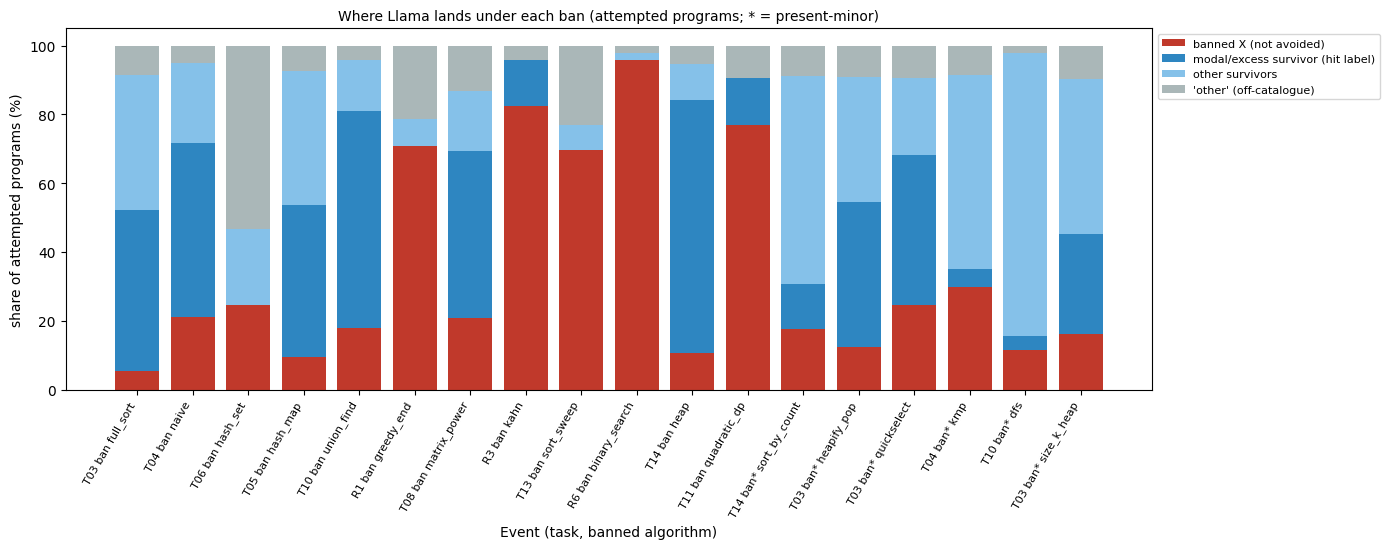

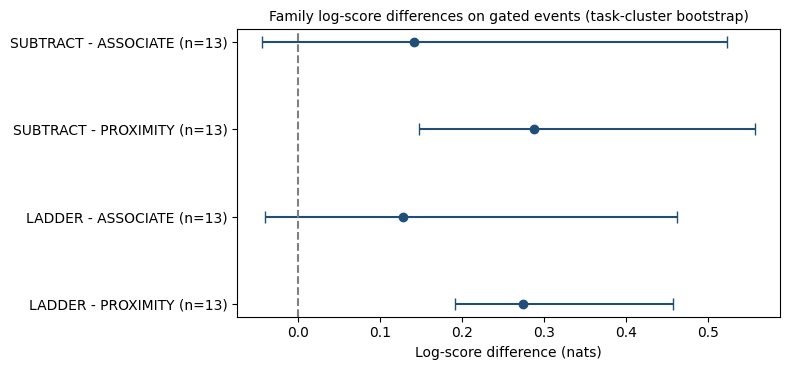

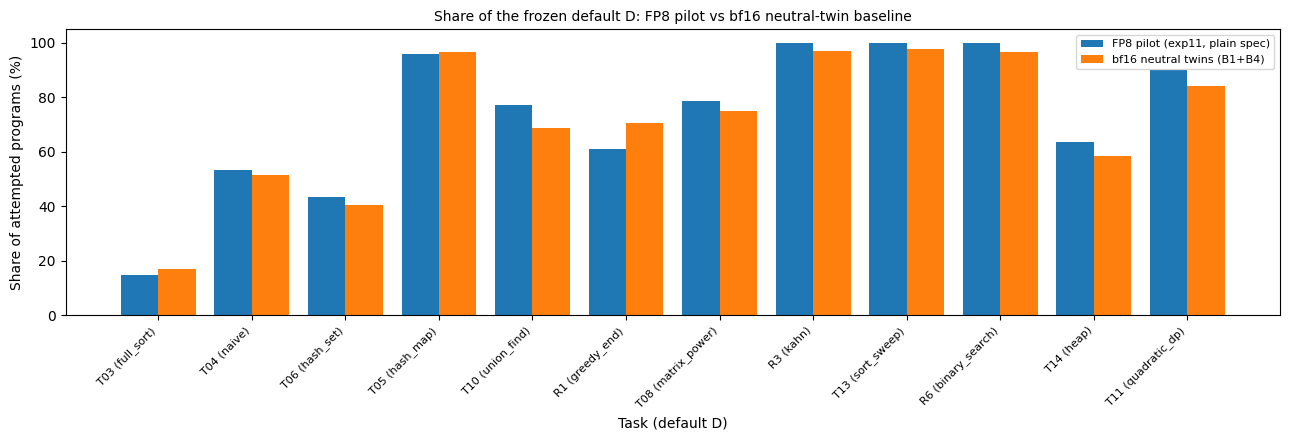

In [30]:
# ---- src/figures.py (specs unchanged; _render draws them with matplotlib instead of the aii-data-fig-gen script)
def _render(spec: dict, name: str) -> None:
    sp = FIGS / f"{name}.json"
    sp.write_text(json.dumps(spec, indent=1))
    cats = spec["categories"]
    if spec["type"] == "stacked_pct":
        fig, ax = plt.subplots(figsize=(14, 5.6))
        tot = np.array([sum(s["values"][i] for s in spec["series"]) or 1 for i in range(len(cats))], dtype=float)
        bottom = np.zeros(len(cats))
        for s, col in zip(spec["series"], ["#c0392b", "#2e86c1", "#85c1e9", "#aab7b8"]):
            v = 100 * np.array(s["values"], dtype=float) / tot
            ax.bar(range(len(cats)), v, bottom=bottom, label=s["label"], color=col)
            bottom += v
        ax.set_ylabel("share of attempted programs (%)")
        ax.set_xticks(range(len(cats)), cats, rotation=60, ha="right", fontsize=8)
        ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    elif spec["type"] == "forest":
        ci = json.loads((RESULTS / "forest_cis.json").read_text())  # asymmetric CIs (the spec stores max(lo, hi))
        fig, ax = plt.subplots(figsize=(8, 3.8))
        y = np.arange(len(cats))[::-1]
        m = np.array(spec["series"][0]["values"])
        lo = np.array([m_ - ci[c]["ci_lo"] for m_, c in zip(m, cats)])
        hi = np.array([ci[c]["ci_hi"] - m_ for m_, c in zip(m, cats)])
        ax.errorbar(m, y, xerr=[lo, hi], fmt="o", capsize=4, color="#1f4e79")
        ax.axvline(spec.get("null_line", 0.0), color="grey", ls="--")
        ax.set_yticks(y, cats)
    else:  # "bar"
        fig, ax = plt.subplots(figsize=(13, 4.5))
        w = 0.8 / len(spec["series"])
        for i, s in enumerate(spec["series"]):
            ax.bar(np.arange(len(cats)) + i * w - 0.4 + w / 2, s["values"], width=w, label=s["label"])
        ax.set_xticks(range(len(cats)), cats, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel(spec.get("ylabel", ""))
        ax.legend(fontsize=8)
    ax.set_title(spec["title"], fontsize=10)
    ax.set_xlabel(spec.get("xlabel", ""))
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", dpi=120)
    plt.show()


def landings() -> None:
    rows = read_jsonl(RESULTS / "c1_events.jsonl")
    cats, banned, hit, surv, other, = [], [], [], [], []
    for r in rows:
        lc = r["landing_counts"]
        n = sum(lc.values()) or 1
        X = r["banned"]
        h = r.get("hit_label")
        cats.append(r["event_id"].replace("|modal|", " ban ").replace("|present_minor|", " ban* "))
        nb = lc.get(X, 0)
        nh = lc.get(h, 0) if h and h not in (X, "other") else 0
        no = lc.get("other", 0)
        banned.append(nb)
        hit.append(nh)
        other.append(no)
        surv.append(max(sum(lc.values()) - nb - nh - no, 0))
    spec = {"type": "stacked_pct", "title": "Where Llama lands under each ban (attempted programs; * = present-minor)",
            "xlabel": "Event (task, banned algorithm)", "aspect": "16:9", "categories": cats,
            "series": [{"label": "banned X (not avoided)", "values": banned},
                       {"label": "modal/excess survivor (hit label)", "values": hit},
                       {"label": "other survivors", "values": surv}, {"label": "'other' (off-catalogue)", "values": other}]}
    _render(spec, "fig1_ban_landings")


def forest() -> None:
    rows = [r for r in read_jsonl(RESULTS / "c1_events.jsonl") if r["gate_pass"]]
    pairs = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]
    rng = np.random.default_rng(0)
    cats, vals, lo, hi = [], [], [], []
    for a, b in pairs:
        d = [(r["task"], r["logscore"][a] - r["logscore"][b]) for r in rows
             if r["logscore"].get(a) is not None and r["logscore"].get(b) is not None]
        if not d:
            continue
        tasks = sorted({t for t, _ in d})
        boots = []
        for _ in range(N_BOOT):  # original: range(2000)
            tk = rng.choice(tasks, size=len(tasks), replace=True)
            boots.append(np.mean([x for t in tk for (tt, x) in d if tt == t]))
        m = float(np.mean([x for _, x in d]))
        cats.append(f"{a} - {b} (n={len(d)})")
        vals.append(round(m, 4))
        lo.append(round(m - float(np.percentile(boots, 2.5)), 4))
        hi.append(round(float(np.percentile(boots, 97.5)) - m, 4))
    if not cats:
        return
    spec = {"type": "forest", "null_line": 0.0, "title": "Family log-score differences on gated events (task-cluster bootstrap)",
            "xlabel": "Log-score difference (nats)",
            "aspect": "4:3", "categories": cats,
            "series": [{"values": vals, "errors": [round(max(l, h), 4) for l, h in zip(lo, hi)]}]}
    (RESULTS / "forest_cis.json").write_text(json.dumps({c: {"mean": v, "ci_lo": v - l, "ci_hi": v + h}
                                                         for c, v, l, h in zip(cats, vals, lo, hi)}, indent=1))
    try:
        _render(spec, "fig2_logscore_forest")
    except Exception as e:  # noqa: BLE001
        logger.error(f"forest failed: {e}")


def baseline_vs_pilot() -> None:
    labels = read_jsonl(DATA / "labels.jsonl")
    ev = read_json(PRED / "events.json")
    cats, pil, bf = [], [], []
    for t, v in ev["tasks"].items():
        D = v["D"]
        p = [r["label"] for r in labels if r["task"] == t and r.get("phase") == "pilot" and r["label"] != "invalid"]
        b = [r["label"] for r in labels if r["task"] == t and r.get("phase") in ("B1", "B4") and r["label"] != "invalid"]
        cats.append(f"{t} ({D})")
        pil.append(round(100 * p.count(D) / max(len(p), 1), 1))
        bf.append(round(100 * b.count(D) / max(len(b), 1), 1))
    spec = {"type": "bar", "title": "Share of the frozen default D: FP8 pilot vs bf16 neutral-twin baseline",
            "xlabel": "Task (default D)", "ylabel": "Share of attempted programs (%)", "aspect": "16:9",
            "categories": cats, "series": [{"label": "FP8 pilot (exp11, plain spec)", "values": pil},
                                           {"label": "bf16 neutral twins (B1+B4)", "values": bf}]}
    _render(spec, "fig3_baseline_vs_pilot")


for fn in (landings, forest, baseline_vs_pilot):
    fn()

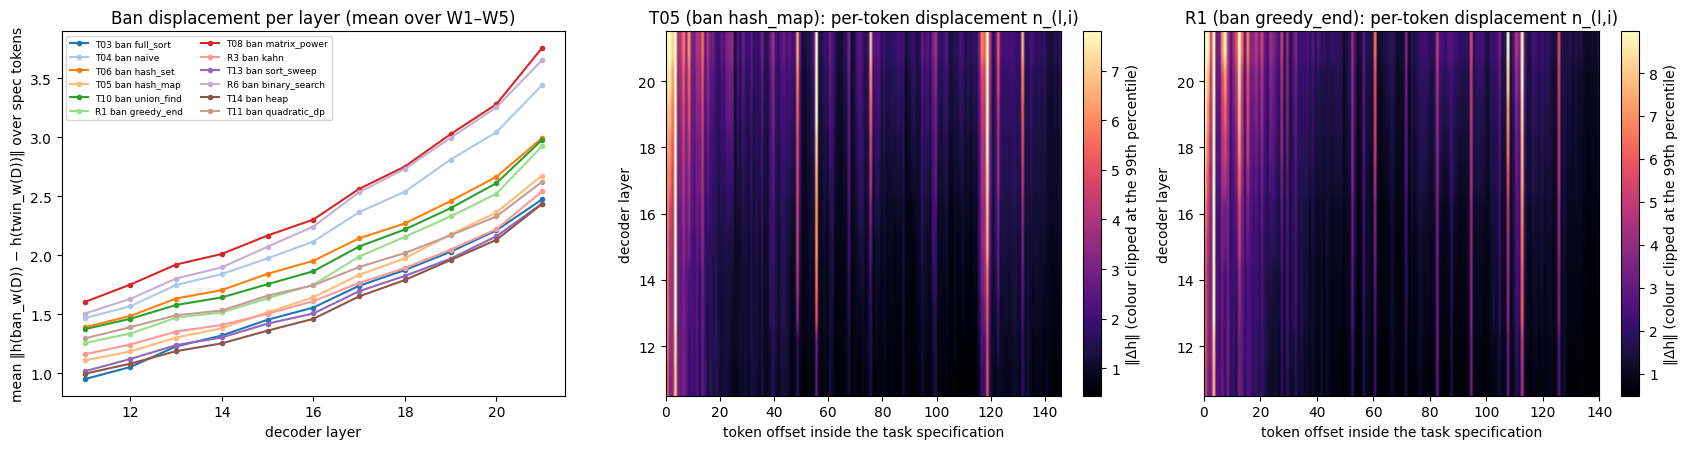

In [31]:
# ---- activation space: how far the ban sentence moves Llama's residual stream at the task-specification tokens
#      (recorded by `method.py hf`; these norms set the size of the LADDER random-direction pushes)
bn = data["metadata"]["ban_norms"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.15, 1, 1]})
cmap = plt.get_cmap("tab20")
for i, (t, v) in enumerate(bn["tasks"].items()):
    axes[0].plot(bn["layers"], v["per_layer_mean"], marker="o", ms=3, color=cmap(i), label=f"{t} ban {v['D']}")
axes[0].set(xlabel="decoder layer", ylabel="mean ‖h(ban_w(D)) − h(twin_w(D))‖ over spec tokens",
            title="Ban displacement per layer (mean over W1–W5)")
axes[0].legend(fontsize=6.5, ncol=2)
for ax, t in zip(axes[1:], bn["full_norms"]):
    M = np.array(bn["full_norms"][t])  # [layer, spec position]
    im = ax.imshow(M, aspect="auto", origin="lower", cmap="magma", vmax=np.percentile(M, 99),
                   extent=[0, M.shape[1], bn["layers"][0] - 0.5, bn["layers"][-1] + 0.5])
    ax.set(xlabel="token offset inside the task specification", ylabel="decoder layer",
           title=f"{t} (ban {bn['tasks'][t]['D']}): per-token displacement n_(l,i)")
    fig.colorbar(im, ax=ax, fraction=0.046, label="‖Δh‖ (colour clipped at the 99th percentile)")
fig.tight_layout()
fig.savefig(FIGS / "fig4_ban_displacement_norms.png", dpi=120)
plt.show()

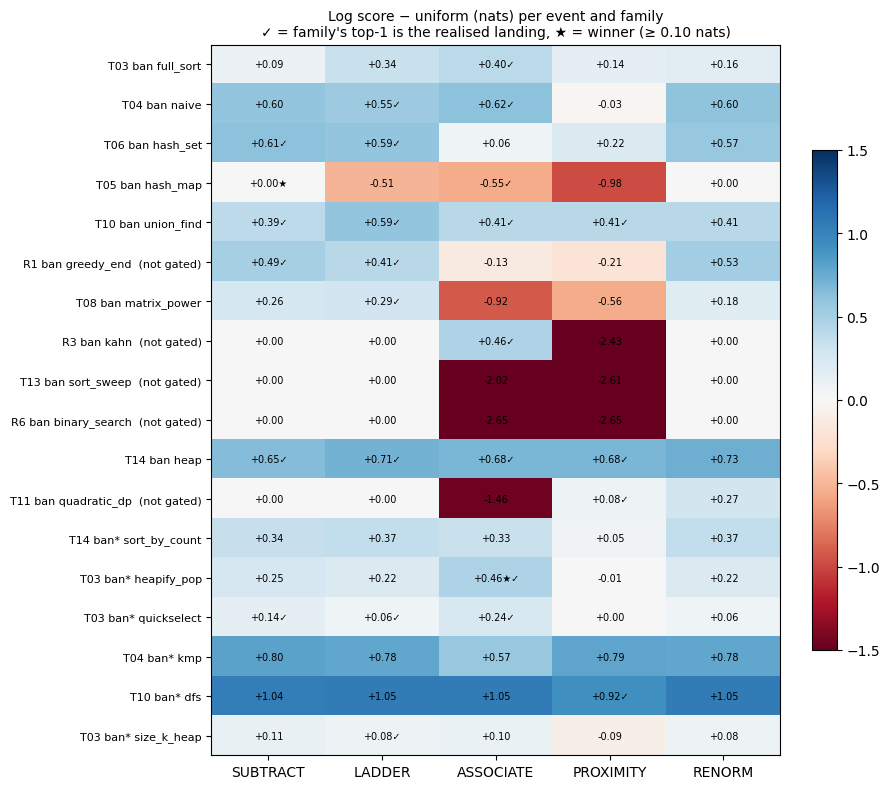

                          event  gated  avoidance      landing (hit) top1 SUBTRACT   top1 LADDER    top1 ASSOCIATE  top1 PROXIMITY    winner  margin
            T03|modal|full_sort   True       0.95        quickselect   heapify_pop         other       quickselect     size_k_heap      None   0.064
                T04|modal|naive   True       0.79                kmp    rabin_karp           kmp               kmp         builtin      None   0.022
             T06|modal|hash_set   True       0.76              other         other         other             floyd   sort_adjacent      None   0.025
             T05|modal|hash_map   True       0.91  sort_two_pointers          None         other sort_two_pointers     brute_force  SUBTRACT   0.512
           T10|modal|union_find   True       0.82                dfs           dfs           dfs               dfs             dfs      None   0.177
            R1|modal|greedy_end  False       0.29              other         other         other         d

In [32]:
# ---- the frozen C1 scoring, event by event: log score of every family relative to the uniform forecast
c1rows = read_jsonl(RESULTS / "c1_events.jsonl")
names = [r["event_id"].replace("|modal|", " ban ").replace("|present_minor|", " ban* ") for r in c1rows]
fams = FAMILIES + ["RENORM"]
M = np.array([[(r["logscore"][f] - r["logscore"]["UNIFORM"]) if r["logscore"].get(f) is not None else np.nan
               for f in fams] for r in c1rows])
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(M, cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
for i, r in enumerate(c1rows):
    for j, f in enumerate(fams):
        mark = ("★" if r["winner"] == f else "") + ("✓" if f in r["top1"] and r["top1"][f] == r["hit_label"] else "")
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i, j]:+.2f}{mark}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(fams)), fams)
ax.set_yticks(range(len(names)), [n + ("" if r["gate_pass"] else "  (not gated)") for n, r in zip(names, c1rows)], fontsize=8)
ax.set_title("Log score − uniform (nats) per event and family\n✓ = family's top-1 is the realised landing, ★ = winner (≥ 0.10 nats)", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
fig.savefig(FIGS / "fig5_logscore_map.png", dpi=120)
plt.show()

summary = pd.DataFrame([{"event": r["event_id"], "gated": r["gate_pass"], "avoidance": round(r["avoidance"], 2),
                         "landing (hit)": r["hit_label"], **{f"top1 {f}": r["top1"][f] for f in FAMILIES},
                         "winner": r["winner"], "margin": round(r["margin"], 3) if r["margin"] is not None else None}
                        for r in c1rows])
print(summary.to_string(index=False))
print(f"\nBRANCH: {res['c1']['branch']}  |  gated {res['c1']['n_gated']}/18, disagreeing & gated "
      f"{res['c1']['n_disagreeing_gated']}, wins {res['c1']['wins']}")

## Takeaways

- **A ban does move Llama, but not always away from X.** On R1, R3, T13, R6 and T11 the default survives the explicit ban (avoidance 0.04–0.30); the model keeps writing it while being told not to. On the other 13 events the ban works, and the landing is *aimed*: LADDER and ASSOCIATE name the realised landing on 7/13 gated events, about twice chance.
- **No forecast family wins under the frozen rule.** Only 2 of 11 disagreeing gated events have a ≥ 0.10-nat winner, so the branch is **NO FAMILY ADVANCES (aimed, unresolved)**. Code proximity is the worst forecaster: SUBTRACT and LADDER beat PROXIMITY, Holm-rejected. ASSOCIATE, SUBTRACT and LADDER cannot be separated at N = 11.
- **Surface-token vetoes rarely remove a default.** Vetoing X's signature n-grams round after round still leaves X at 0.80–0.96 of attempts on T05, T13, R3, R6 and T11. Only T14's heap is all but removed (0.02). The default is not carried by a few surface tokens.
- **Fragile.** Three sensitivities (correct-only, bf16-only decision set, dropping W4) flip the verdict to SUBSTITUTION (ASSOCIATE). This within-Llama result is meant to be pooled with the Qwen rows (`results/c1_events.jsonl`, shared schema), not read alone.

To run the full pipeline, use the artifact's repository on an L4-class GPU (`method.py setup … analyse`, about 1.8 GPU-hours plus about USD 0.48 of judge calls). In this notebook, set `PROX_N_EVENTS`, `PROX_K` and `PROX_K_TOK` to scale PROXIMITY toward the original k = 10 on all 18 events.